# EDA dan ablasi machine learning klasifikasi tanaman dari citra daun


In [1]:
from pathlib import Path
import os, sys, json, time, hashlib, platform, warnings
from functools import lru_cache
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import cv2
import sklearn
from sklearn.cluster import MiniBatchKMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits
from IPython.display import display

SMOKE_TEST = False
SEED = 42
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'Dataset/metadata.csv').exists()), None)
assert ROOT is not None, 'Jalankan dari direktori proyek atau Notebook.'
# Kandidat augmentasi: dibuat hanya dari subset train di setiap fit.
AUGMENTATION_ENABLED = True
AUGMENT_TYPES = ('gaussian_noise','flip','rotation','corruption','brightness','contrast')
AUGMENT_COPIES_PER_TYPE = 1
AUGMENT_CONFIG = dict(noise_sigma=(3.,10.),corruption_fraction=(.002,.008),
    brightness_delta=(10.,20.),contrast_factor=(.85,1.15))
OUT = ROOT/'Notebook'/(('hasil_ml_smoke' if SMOKE_TEST else 'hasil_ml_full')+
    ('_aug' if AUGMENTATION_ENABLED else ''))
OUT.mkdir(parents=True, exist_ok=True)
MAX_SIDE = 256 if SMOKE_TEST else 640
OUTER_FOLDS = 2 if SMOKE_TEST else 5
INNER_FOLDS = 3
N_TREES = 12 if SMOKE_TEST else 200
PERM_REPEATS = 2 if SMOKE_TEST else 10

cv2.setNumThreads(1)
thread_limits = threadpool_limits(limits=1)
environment = dict(python=sys.executable, version=sys.version, sklearn=sklearn.__version__,
                   opencv=cv2.__version__, platform=platform.platform(), smoke=SMOKE_TEST)

from importlib.metadata import version as package_version, PackageNotFoundError
try:
    environment['torch_installed_version'] = package_version('torch')
except PackageNotFoundError:
    environment['torch_installed_version'] = None
environment['cuda_available'] = None
environment['gpu'] = None
environment['gpu_probe_status'] = 'Tidak diperiksa; notebook ML menggunakan CPU tanpa impor PyTorch.'
environment['model_backend'] = 'scikit-learn CPU; OpenCV CPU'
display(environment)

environment['augmentation']=dict(enabled=AUGMENTATION_ENABLED,types=AUGMENT_TYPES,copies=AUGMENT_COPIES_PER_TYPE,config=AUGMENT_CONFIG)
(OUT/'augmentation_config.json').write_text(json.dumps(environment['augmentation'],indent=2),encoding='utf-8')


{'python': 'd:\\AnacondaPython\\envs\\ai_env\\python.exe',
 'version': '3.10.20 | packaged by conda-forge | (main, Mar  5 2026, 16:36:49) [MSC v.1944 64 bit (AMD64)]',
 'sklearn': '1.7.2',
 'opencv': '5.0.0',
 'platform': 'Windows-10-10.0.26300-SP0',
 'smoke': False,
 'torch_installed_version': '2.11.0+cu128',
 'cuda_available': None,
 'gpu': None,
 'gpu_probe_status': 'Tidak diperiksa; notebook ML menggunakan CPU tanpa impor PyTorch.',
 'model_backend': 'scikit-learn CPU; OpenCV CPU'}

395

## 1. EDA dan audit metadata

Audit jumlah kelas, dimensi/aspect ratio, brightness, blur (variansi Laplacian), exact duplicate berbasis piksel RGB berorientasi EXIF, dan contact sheet. Brightness/blur adalah indikator eksploratif, bukan dasar otomatis membuang foto sulit. Tidak ada penghapusan berdasarkan kegagalan mask. Jika ada kolom `status_QC_label`, notebook mengharuskan nilainya `approved` untuk benchmark final; tanpa kolom itu status label tetap belum diverifikasi.

,jumlah_foto
label,
Aglaonema,10
Daun nangka,9
Kamboja jepang,9
Lidah metua,12
Paku tanduk rusa,14
Peperomium semangka,6


width             height                brightness  \
                      min median  max    min  median   max         min   
label                                                                    
Aglaonema             960  960.0  960   1280  1280.0  1280  107.453114   
Daun nangka           960  960.0  960   1280  1280.0  1280  101.822860   
Kamboja jepang        960  960.0  960   1280  1280.0  1280  120.920500   
Lidah metua           960  960.0  960   1280  1280.0  1280  121.183942   
Paku tanduk rusa      960  960.0  960   1280  1280.0  1280  104.178812   
Peperomium semangka   960  960.0  960   1280  1280.0  1280  110.603520   

                                            blur_laplacian              \
                         median         max            min      median   
label                                                                    
Aglaonema            121.746889  127.418547      66.990818  113.573388   
Daun nangka          121.134946  130.789189     105.753242  254.333890   
Kamboja jepang       132.582237  147.228861      18.196577   50.291000   
Lidah metua          143.618368  168.126633      24.476553   96.681383   
Paku tanduk rusa     113.492766  125.403037     129.113686  810.529554   
Peperomium semangka  116.444705  126.558483     105.348281  165.247043   

                                  
                             max  
label                             
Aglaonema             264.322987  
Daun nangka           821.554799  
Kamboja jepang        387.818156  
Lidah metua          2677.020240  
Paku tanduk rusa     1676.571017  
Peperomium semangka   658.083737

,image,label,pixel_hash


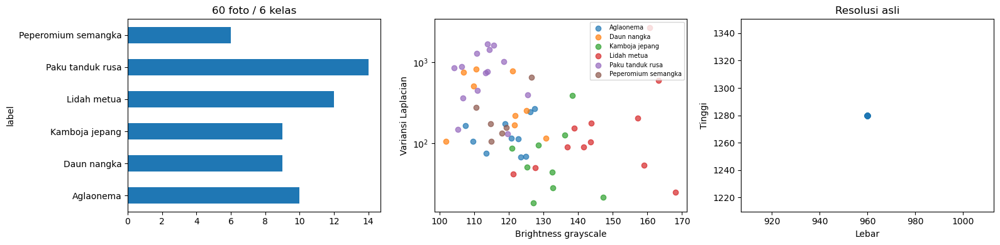

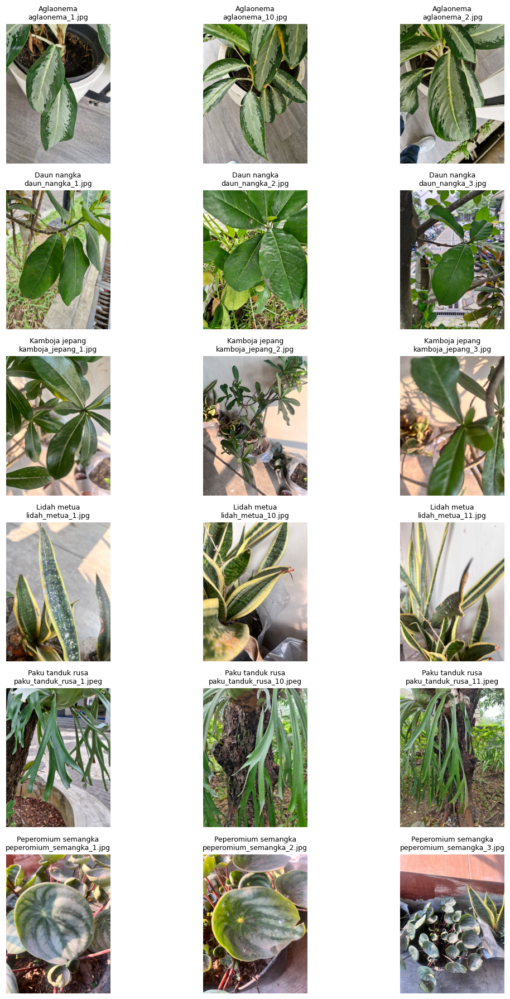

Tinjau semua label, khususnya foto dengan beberapa jenis tanaman. Tidak ada asumsi identitas botani/UB dari gambar.


In [2]:
meta = pd.read_csv(ROOT/'Dataset/metadata.csv')
assert {'image','label'} <= set(meta.columns)
assert not meta[['image','label']].isna().any().any()
assert not meta.image.duplicated().any(), 'image_id harus unik.'
meta['path'] = [str(ROOT/'Dataset'/str(r.label)/str(r.image)) for r in meta.itertuples()]
records = []
for r in meta.itertuples():
    p = Path(r.path)
    assert p.is_file(), p
    with Image.open(p) as im:
        rgb = np.asarray(ImageOps.exif_transpose(im).convert('RGB'))
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    records.append(dict(width=rgb.shape[1], height=rgb.shape[0], aspect=rgb.shape[1]/rgb.shape[0],
        brightness=float(gray.mean()), blur_laplacian=float(cv2.Laplacian(gray, cv2.CV_64F).var()),
        pixel_hash=hashlib.sha256(str(rgb.shape).encode()+rgb.tobytes()).hexdigest()))
meta = pd.concat([meta, pd.DataFrame(records)], axis=1)
assert meta.groupby('pixel_hash').label.nunique().max() == 1, 'Duplikat dengan label konflik: perbaiki dahulu.'
counts = meta.groupby('label').size().rename('jumlah_foto')
display(counts.to_frame(), meta.groupby('label')[['width','height','brightness','blur_laplacian']].agg(['min','median','max']))
display(meta[meta.pixel_hash.duplicated(keep=False)][['image','label','pixel_hash']])
fig, ax = plt.subplots(1,3,figsize=(16,4))
counts.plot.barh(ax=ax[0], title=f'{len(meta)} foto / {len(counts)} kelas')
for label, d in meta.groupby('label'):
    ax[1].scatter(d.brightness, d.blur_laplacian, label=label, alpha=.7)
ax[1].set(xlabel='Brightness grayscale', ylabel='Variansi Laplacian', yscale='symlog')
ax[1].legend(fontsize=7)
ax[2].scatter(meta.width, meta.height); ax[2].set(xlabel='Lebar',ylabel='Tinggi',title='Resolusi asli')
plt.tight_layout(); plt.show()
meta.to_csv(OUT/'manifest_audit.csv', index=False)
fig, axes = plt.subplots(len(counts), 3, figsize=(12,3*len(counts)), squeeze=False)
for row,(label,d) in enumerate(meta.groupby('label')):
    for col,(_,r) in enumerate(d.head(3).iterrows()):
        with Image.open(r.path) as im:
            axes[row,col].imshow(ImageOps.exif_transpose(im))
        axes[row,col].set_title(f'{label}\n{r.image}', fontsize=9)
    for a in axes[row]: a.axis('off')
plt.tight_layout(); plt.show()
print('Tinjau semua label, khususnya foto dengan beberapa jenis tanaman. Tidak ada asumsi identitas botani/UB dari gambar.')

### 1b. Contoh augmentasi dan protokol train-only

Panel menampilkan foto asli dan enam varian untuk satu foto tiap kelas. Gaussian noise sigma 3-10, flip H/V, rotasi 90/180/270 (tanpa crop atau padding sintetis), salt-and-pepper ringan sebagai corruption, brightness +/-10-20, contrast faktor 0,85-1,15 adalah konfigurasi kandidat.

SVM/RF memakai batch fit: citra dibuat saat persiapan fit, bukan per epoch. Satu foto train menghasilkan asli + enam varian. Augmentasi dilakukan sebelum PCD, hanya dari inner-train saat tuning dan outer-train saat final fit; validation/test tetap asli. Pratinjau EDA tidak menambahkan sampel ke metadata atau split.

Kamus BoVW hanya belajar dari foto asli train, lalu dipakai juga untuk varian. Imputer/scaler/model belajar dari fitur asli + varian train. Fitur augmentasi di-cache untuk konsistensi kandidat grid. Hasil `_aug` terpisah dari baseline; bandingkan dengan split dan seed sama. Augmentasi tidak menambah individu tanaman independen, dan skor tinggi/rendah saja belum membuktikan overfitting.


Pratinjau memakai panel besar 2 x 4 untuk satu foto. Mode `illustration` memperkuat efek khusus tampilan EDA, dengan parameter tertulis pada gambar. Mode `training` menampilkan konfigurasi training yang sebenarnya. Pengaturan contoh visual ini tidak mengubah intensitas augmentasi training. Corruption ditampilkan sebagai salt-and-pepper dan disertai detail piksel yang berubah.


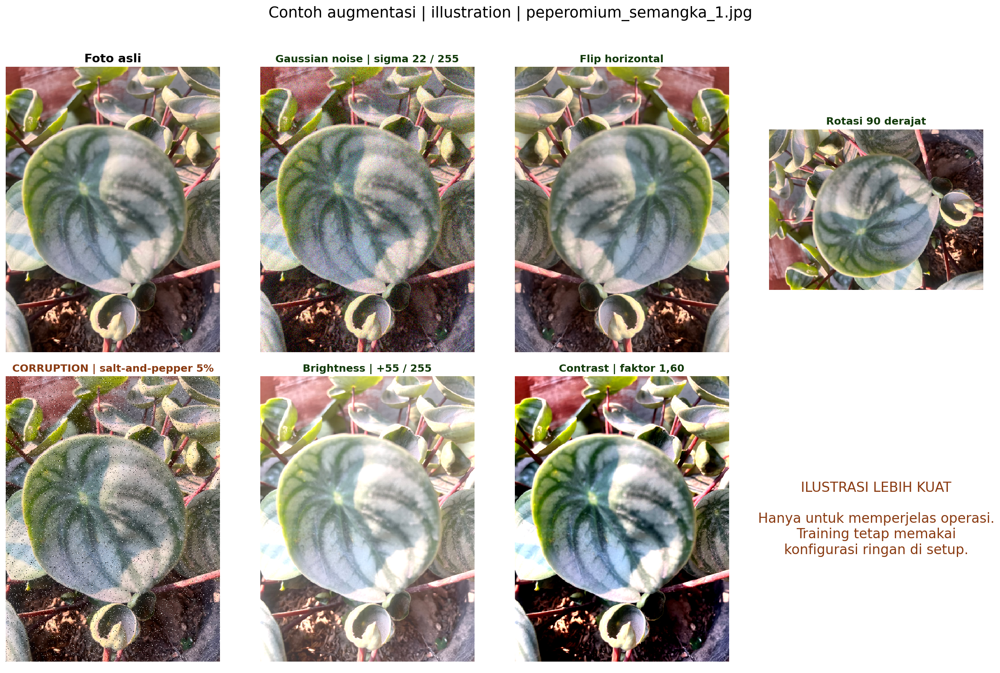

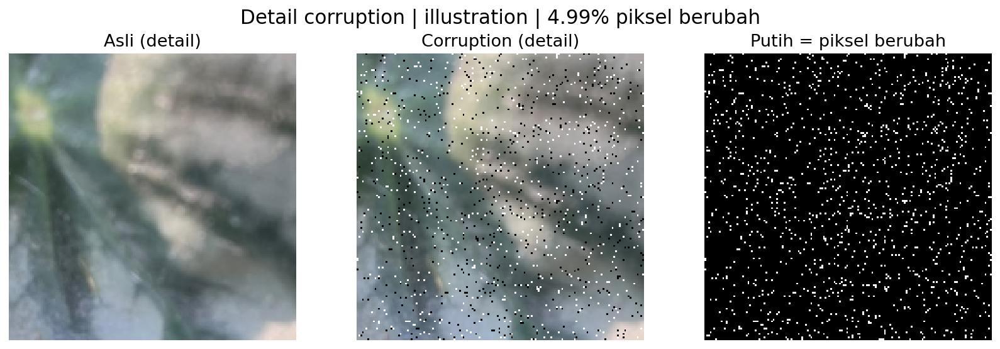

In [ ]:
def augment_rgb(rgb,kind,rng):
    """Konfigurasi kandidat; mengubah array baru, bukan file sumber."""
    x=rgb.astype(np.float32)
    if kind=='gaussian_noise':
        x+=rng.normal(0,rng.uniform(*AUGMENT_CONFIG['noise_sigma']),x.shape).astype(np.float32)
    elif kind=='flip':
        x=np.flip(x,axis=int(rng.integers(0,2))).copy()
    elif kind=='rotation':
        x=np.rot90(x,k=int(rng.integers(1,4))).copy()
    elif kind=='corruption':
        fraction=rng.uniform(*AUGMENT_CONFIG['corruption_fraction'])
        u=rng.random(x.shape[:2]); x[u<fraction/2]=0; x[(u>=fraction/2)&(u<fraction)]=255
    elif kind=='brightness':
        x+=rng.uniform(*AUGMENT_CONFIG['brightness_delta'])*rng.choice([-1.,1.])
    elif kind=='contrast':
        center=x.mean(axis=(0,1),keepdims=True)
        x=(x-center)*rng.uniform(*AUGMENT_CONFIG['contrast_factor'])+center
    else: raise ValueError(kind)
    return np.ascontiguousarray(np.clip(np.rint(x),0,255).astype(np.uint8))

# Panel besar untuk menjelaskan operasi augmentasi.
# 'illustration' lebih kuat agar terlihat jelas. 'training' memakai fungsi training persis.
EDA_AUGMENT_MODE = 'illustration'
EDA_EXAMPLE_IMAGE = 'peperomium_semangka_1.jpg'
assert EDA_AUGMENT_MODE in ('illustration','training')
eda_choice=meta.loc[meta.image.eq(EDA_EXAMPLE_IMAGE)]
assert not eda_choice.empty, 'Ubah EDA_EXAMPLE_IMAGE ke nama foto yang ada di metadata.'
eda_record=eda_choice.iloc[0]
with Image.open(eda_record.path) as eda_im:
    eda_im=ImageOps.exif_transpose(eda_im).convert('RGB')
    eda_im.thumbnail((640,640))
    eda_rgb=np.asarray(eda_im).copy()

def eda_illustration(rgb,kind,rng):
    # Fungsi ini khusus pratinjau, tidak dipanggil oleh training_matrix.
    x=rgb.astype(np.float32)
    if kind=='gaussian_noise':
        x+=rng.normal(0,22,x.shape).astype(np.float32)
        text='Gaussian noise | sigma 22 / 255'
    elif kind=='flip':
        x=np.flip(x,axis=1).copy();text='Flip horizontal'
    elif kind=='rotation':
        x=np.rot90(x,1).copy();text='Rotasi 90 derajat'
    elif kind=='corruption':
        u=rng.random(x.shape[:2]);x[u<.025]=0;x[(u>=.025)&(u<.05)]=255
        text='CORRUPTION | salt-and-pepper 5%'
    elif kind=='brightness':
        x+=55;text='Brightness | +55 / 255'
    elif kind=='contrast':
        mean=x.mean(axis=(0,1),keepdims=True)
        x=(x-mean)*1.6+mean;text='Contrast | faktor 1,60'
    else: raise ValueError(kind)
    return np.ascontiguousarray(np.clip(np.rint(x),0,255).astype(np.uint8)),text

eda_labels={'gaussian_noise':'Gaussian noise | sigma '+str(AUGMENT_CONFIG['noise_sigma']),
    'flip':'Flip horizontal / vertikal','rotation':'Rotasi 90 / 180 / 270 derajat',
    'corruption':'CORRUPTION | salt-and-pepper '+str(AUGMENT_CONFIG['corruption_fraction']),
    'brightness':'Brightness | +/- '+str(AUGMENT_CONFIG['brightness_delta']),
    'contrast':'Contrast | faktor '+str(AUGMENT_CONFIG['contrast_factor'])}
eda_variants={}
eda_fig,eda_axes=plt.subplots(2,4,figsize=(18,12),squeeze=False)
eda_axes.flat[0].imshow(eda_rgb,interpolation='nearest')
eda_axes.flat[0].set_title('Foto asli',fontsize=15,fontweight='bold')
for eda_index,eda_kind in enumerate(AUGMENT_TYPES,1):
    eda_rng=np.random.default_rng(np.random.SeedSequence([SEED,int(eda_choice.index[0]),eda_index,0]))
    if EDA_AUGMENT_MODE=='illustration':
        eda_result,eda_label=eda_illustration(eda_rgb,eda_kind,eda_rng)
    else:
        eda_result=augment_rgb(eda_rgb,eda_kind,eda_rng);eda_label=eda_labels[eda_kind]
    eda_variants[eda_kind]=eda_result
    eda_axes.flat[eda_index].imshow(eda_result,interpolation='nearest')
    eda_axes.flat[eda_index].set_title(eda_label,fontsize=13,fontweight='bold',
        color='#8A3B12' if eda_kind=='corruption' else '#123A0A')
eda_message=('ILUSTRASI LEBIH KUAT\n\nHanya untuk memperjelas operasi.\nTraining tetap memakai\nkonfigurasi ringan di setup.'
             if EDA_AUGMENT_MODE=='illustration' else
             'KONFIGURASI TRAINING\n\nVarian dibuat dengan fungsi\naugment_rgb yang sama\ndengan training.')
eda_axes.flat[7].text(.5,.5,eda_message,ha='center',va='center',fontsize=17,
    color='#8A3B12' if EDA_AUGMENT_MODE=='illustration' else '#123A0A',transform=eda_axes.flat[7].transAxes)
for eda_ax in eda_axes.flat:eda_ax.axis('off')
eda_fig.suptitle('Contoh augmentasi | '+EDA_AUGMENT_MODE+' | '+str(eda_record.image),fontsize=19)
eda_fig.tight_layout(rect=(0,0,1,.96))
eda_output=OUT/('eda_augmentasi_'+EDA_AUGMENT_MODE+'.png')
eda_fig.savefig(eda_output,dpi=140,bbox_inches='tight')
plt.show();plt.close(eda_fig)

# Detail corruption pada area tengah yang sama, tanpa memperbesar intensitas lagi.
eda_corrupt=eda_variants['corruption'];eda_h,eda_w=eda_rgb.shape[:2]
eda_y=max(0,(eda_h-160)//2);eda_x=max(0,(eda_w-160)//2)
eda_crop=(slice(eda_y,eda_y+160),slice(eda_x,eda_x+160))
eda_changed=np.any(eda_corrupt!=eda_rgb,axis=2)
eda_detail,eda_detail_axes=plt.subplots(1,3,figsize=(12,4))
eda_detail_axes[0].imshow(eda_rgb[eda_crop],interpolation='nearest')
eda_detail_axes[1].imshow(eda_corrupt[eda_crop],interpolation='nearest')
eda_detail_axes[2].imshow(eda_changed[eda_crop],cmap='gray',vmin=0,vmax=1,interpolation='nearest')
for eda_ax,eda_title in zip(eda_detail_axes,['Asli (detail)','Corruption (detail)','Putih = piksel berubah']):
    eda_ax.set_title(eda_title,fontsize=14);eda_ax.axis('off')
eda_detail.suptitle(f'Detail corruption | {EDA_AUGMENT_MODE} | {100*eda_changed.mean():.2f}% piksel berubah',fontsize=16)
eda_detail.tight_layout()
eda_detail_output=OUT/('eda_corruption_detail_'+EDA_AUGMENT_MODE+'.png')
eda_detail.savefig(eda_detail_output,dpi=140,bbox_inches='tight')
plt.show();plt.close(eda_detail)
print('Pratinjau:',eda_output)
print('Detail corruption:',eda_detail_output)
print('Mode EDA tidak mengubah AUGMENT_CONFIG atau proses training.')


## 2. Protokol split dan kontrol kebocoran

Outer CV menyimpan prediksi out-of-fold (OOF) untuk setiap kombinasi. Inner CV memilih parameter hanya dari outer-train. Split identik untuk seluruh input/paket/model; kamus BoVW di-fit ulang pada inner-train, lalu outer-train. `plant_id` dipakai bila lengkap; grup yang terlalu sedikit menghentikan evaluasi dengan pesan, bukan diam-diam beralih ke foto. Tanpa `plant_id`, exact duplicate dikelompokkan; foto terkait yang tidak identik masih dapat bocor dan harus dilengkapi metadata tanamannya.

Untuk kontrol fitur, profil ekstraksi dipilih pada inner CV **K0–F8–SVM sebagai anchor**, lalu dibekukan bersama untuk semua 108 kombinasi dalam outer fold. Ini pencarian terbatas yang terkontrol, bukan optimasi seluruh parameter tiap perlakuan. Parameter PCD dibekukan *a priori* sebagai kandidat awal MD: CLAHE L* 1,5 / 8×8, tanpa smoothing; K-Means Lab K=4; morfologi 3×3. Tidak diklaim sebagai parameter PCD terbaik. Ruang pencarian dapat diperluas dengan mengubah protokol sebelum evaluasi, bukan setelah melihat hasil OOF.

In [ ]:
y = meta.label.to_numpy()
LABELS = sorted(meta.label.unique())
has_plants = 'plant_id' in meta and meta.plant_id.notna().all() and meta.plant_id.astype(str).str.strip().ne('').all()
if 'plant_id' in meta and not has_plants:
    raise ValueError('plant_id terisi sebagian: lengkapi seluruhnya atau hapus kolom untuk eksplorasi foto yang dinyatakan jelas.')
GROUPED = has_plants or meta.pixel_hash.duplicated().any()
groups = meta.plant_id.astype(str).to_numpy() if has_plants else meta.pixel_hash.to_numpy()
PROTOCOL = 'plant-group CV' if has_plants else 'EKSPLORATIF foto (duplikat identik satu grup)'
print(PROTOCOL)
if 'status_QC_label' in meta:
    assert meta.status_QC_label.eq('approved').all(), 'Selesaikan QC label pada seluruh daftar benchmark.'
else:
    warnings.warn('status_QC_label belum tersedia; hasil bersifat provisional.')

def split_indices(indices, n_splits, seed):
    indices = np.asarray(indices)
    if GROUPED:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        iterator = cv.split(indices, y[indices], groups[indices])
    else:
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        iterator = cv.split(indices, y[indices])
    result = []
    for a,b in iterator:
        tr,va = indices[a],indices[b]
        if set(y[tr]) != set(LABELS) or set(y[va]) != set(LABELS):
            raise ValueError('Grup/foto tidak cukup untuk semua kelas pada fold train dan evaluasi. Tambah individu atau sesuaikan fold.')
        assert not set(meta.iloc[tr].pixel_hash) & set(meta.iloc[va].pixel_hash)
        if GROUPED: assert not set(groups[tr]) & set(groups[va])
        result.append((tr,va))
    return result

outer = split_indices(np.arange(len(meta)), OUTER_FOLDS, SEED)
inner = {f:split_indices(tr, INNER_FOLDS, SEED+f+1) for f,(tr,te) in enumerate(outer)}
split_rows = [dict(fold=f, image=meta.iloc[i].image, role=role, group=groups[i])
              for f,(tr,te) in enumerate(outer) for role,idx in [('train',tr),('evaluation',te)] for i in idx]
pd.DataFrame(split_rows).to_csv(OUT/'splits.csv',index=False)
CONDITIONS = {'N':('K0',False,None), 'E':('K1',True,None),
    'S-O':('K2',False,'otsu'), 'S-K':('K2',False,'kmeans'),
    'E-S-O':('K3',True,'otsu'), 'E-S-K':('K3',True,'kmeans')}
PACKAGES = {'F0':('color',), 'F1':('color','sobel'), 'F2':('color','canny'),
    'F3':('bovw',), 'F4':('color','bovw'), 'F5':('canny','bovw'),
    'F6':('sobel','bovw'), 'F7':('color','canny','bovw'), 'F8':('color','sobel','bovw')}
PROFILES = [dict(bins=(12,6,6), words=20, low=50, high=100),
            dict(bins=(8,4,4), words=10, low=30, high=80),
            dict(bins=(16,8,8), words=40, low=80, high=160)]
if SMOKE_TEST: PROFILES = PROFILES[:1]
display(pd.DataFrame([dict(input=k,condition=v[0],enhancement=v[1],segmenter=v[2]) for k,v in CONDITIONS.items()]))

EKSPLORATIF foto (duplikat identik satu grup)


C:\Users\arsyad\AppData\Local\Temp\ipykernel_21992\809961849.py:13: UserWarning: status_QC_label belum tersedia; hasil bersifat provisional.
  warnings.warn('status_QC_label belum tersedia; hasil bersifat provisional.')


,input,condition,enhancement,segmenter
0,N,K0,False,None
1,E,K1,True,None
2,S-O,K2,False,otsu
3,S-K,K2,False,kmeans
4,E-S-O,K3,True,otsu
5,E-S-K,K3,True,kmeans


## 3. PCD full frame dan QC mask

Aturan K-Means awal yang eksplisit: centroid dengan a* < 128 digabung sebagai kandidat hijau; bila tidak ada, ambil centroid a* terkecil. Ini prior warna lintas kelas, **bukan** deteksi semantik daun atau hasil kalibrasi ROI lama. Sampel piksel deterministik dipakai untuk fit per gambar, kemudian seluruh piksel dipetakan ke centroid. K/seed/aturan yang sama dipakai pada K2 dan K3.

Mask kosong/hampir penuh tetap dicatat dan foto tetap dievaluasi. Tidak mengganti mask dengan ROI, mask manual, atau seluruh frame. Tanpa GT full frame yang ditinjau, notebook tidak menghitung IoU/Dice.

,mask_fraction,mask_empty,mask_near_full,pcd_s
input,,,,
E,1.000000,0.0,0.000000,0.007430
E-S-K,0.778496,0.0,0.550000,0.023447
E-S-O,0.459881,0.0,0.000000,0.006986
N,1.000000,0.0,0.000000,0.001018
S-K,0.712269,0.0,0.316667,0.078816
S-O,0.450979,0.0,0.000000,0.002462


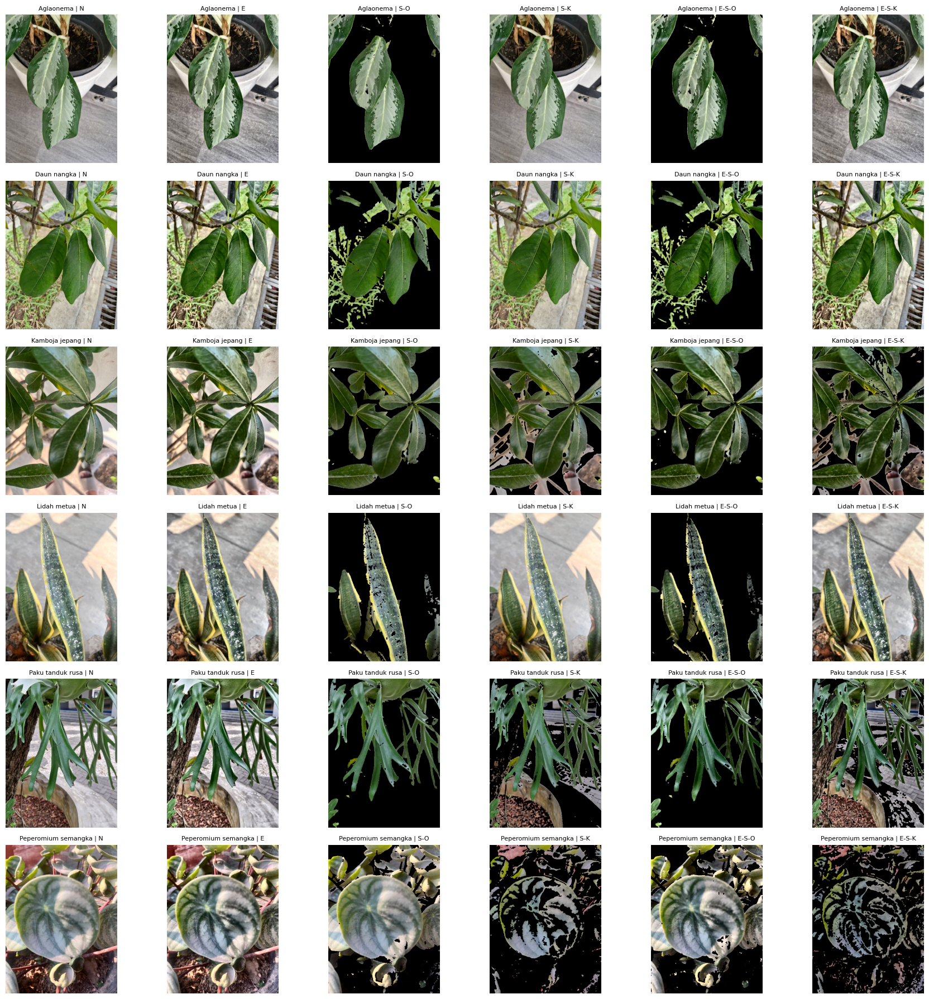

In [5]:
def process_rgb(rgb,condition):
    rgb=rgb.copy()
    _,enhance,segmenter = CONDITIONS[condition]
    if enhance:
        lab = cv2.cvtColor(rgb,cv2.COLOR_RGB2LAB)
        lab[:,:,0] = cv2.createCLAHE(clipLimit=1.5,tileGridSize=(8,8)).apply(lab[:,:,0])
        rgb = cv2.cvtColor(lab,cv2.COLOR_LAB2RGB)
    mask = np.ones(rgb.shape[:2], dtype=np.uint8)
    threshold = np.nan
    if segmenter == 'otsu':
        a = cv2.cvtColor(rgb,cv2.COLOR_RGB2LAB)[:,:,1]
        threshold, mask = cv2.threshold(a,0,1,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
    elif segmenter == 'kmeans':
        lab = cv2.cvtColor(rgb,cv2.COLOR_RGB2LAB).reshape(-1,3).astype(np.float32)
        rng = np.random.default_rng(SEED)
        sample = lab[rng.choice(len(lab),min(len(lab),5000),replace=False)]
        km = MiniBatchKMeans(n_clusters=4,random_state=SEED,n_init=3,batch_size=512).fit(sample)
        foreground = np.flatnonzero(km.cluster_centers_[:,1] < 128)
        if len(foreground)==0: foreground = [km.cluster_centers_[:,1].argmin()]
        mask = np.isin(km.predict(lab),foreground).reshape(rgb.shape[:2]).astype(np.uint8)
    if segmenter:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(3,3))
        mask = cv2.morphologyEx(mask,cv2.MORPH_OPEN,kernel)
        mask = cv2.morphologyEx(mask,cv2.MORPH_CLOSE,kernel)
    return rgb,mask.astype(bool),threshold

LOAD_TIMES = {}
@lru_cache(maxsize=None)
def load_rgb(i):
    clock = time.perf_counter()
    with Image.open(meta.iloc[i].path) as im:
        im = ImageOps.exif_transpose(im).convert('RGB')
        w,h = im.size
        scale = min(1., MAX_SIDE/max(w,h))
        im = im.resize((max(1,round(w*scale)), max(1,round(h*scale))), Image.Resampling.LANCZOS)
        rgb = np.asarray(im).copy()
        LOAD_TIMES[i] = time.perf_counter()-clock
        return rgb

@lru_cache(maxsize=None)
def processed(i, condition):
    t0 = time.perf_counter()
    rgb = load_rgb(i).copy()
    decode_s = LOAD_TIMES[i]  # Biaya persiapan yang sama, termasuk pada cache hit kondisi lain.
    t0 = time.perf_counter()
    rgb,mask,threshold = process_rgb(rgb,condition)
    segmenter = CONDITIONS[condition][2]
    fraction = float(mask.mean())
    return rgb, mask.astype(bool), dict(image=meta.iloc[i].image,input=condition,
        decode_resize_s=decode_s,pcd_s=time.perf_counter()-t0,mask_fraction=fraction,
        mask_empty=fraction==0,mask_near_full=bool(segmenter and fraction>.98),
        otsu_threshold=threshold)

qc = pd.DataFrame([processed(i,c)[2] for c in CONDITIONS for i in range(len(meta))])
qc.to_csv(OUT/'qc_pcd.csv', index=False)
display(qc.groupby('input')[['mask_fraction','mask_empty','mask_near_full','pcd_s']].mean())
fig, axes = plt.subplots(len(LABELS),6,figsize=(18,3*len(LABELS)),squeeze=False)
for row,label in enumerate(LABELS):
    i = int(meta.index[meta.label.eq(label)][0])
    for col,c in enumerate(CONDITIONS):
        rgb,mask,_ = processed(i,c)
        axes[row,col].imshow(np.where(mask[:,:,None],rgb,0))
        axes[row,col].set_title(f'{label} | {c}',fontsize=8); axes[row,col].axis('off')
plt.tight_layout(); plt.show()

## 4. Ekstraksi warna, edge, dan SIFT → BoVW

Warna: histogram marginal HSV + mean/std/skewness S dan V (skewness nol bila variansi nol); seluruh H tetap dihitung termasuk saturasi rendah, aturan tetap pada semua input. Sobel: mean/std magnitudo + histogram arah 8 bin berbobot magnitudo. Canny: density + mean magnitudo pada edge + histogram arah 8 bin. Histogram arah dinormalisasi L1; arah modulo 180°. Gaussian Canny 5×5 sigma 1; Sobel 3×3. Gradien dihitung **sebelum** background dihitamkan; domain edge dierosi radius 4 (termasuk frame) sesuai dukungan Gaussian+Sobel.

SIFT dihitung pada grayscale kondisi, bukan peta edge. Keypoint hanya diterima bila dukungan patch konservatif (radius ceil(6 × keypoint.size)) berada di domain; patch yang memotong mask/frame ditolak. Maksimal 100 deskriptor/foto smoke, 300 full. BoVW memakai kamus train bersama antar F3–F8, encoding L1. Tanpa keypoint → nol; domain kosong → fitur terkait NaN, diimputasi median train (kolom train seluruhnya kosong dipertahankan sebagai nol). Jika total deskriptor train < ukuran kamus, konfigurasi dihentikan dengan pesan; tidak meminjam test.

Profil pencarian memasangkan bin warna, V, dan threshold Canny pada tiga kandidat, bukan grid Cartesian penuh. Dimensi contoh profil awal: **30/40/40/20/50/30/30/60/60**; dimensi aktual dicatat per fold.

In [6]:
def hist_orientation(mag,theta,domain):
    h = np.histogram(theta[domain],bins=8,range=(0,180),weights=mag[domain])[0].astype(float)
    return h/max(h.sum(),1e-12)

def extract_rgb_features(rgb,mask,pid,source_seed):
    p = PROFILES[pid]
    clock = time.perf_counter()
    hsv = cv2.cvtColor(rgb,cv2.COLOR_RGB2HSV).astype(float)
    color = []
    for ch,bins,limit in zip(range(3),p['bins'],(180,256,256)):
        h = np.histogram(hsv[:,:,ch][mask],bins=bins,range=(0,limit))[0].astype(float)
        color.extend(h/max(h.sum(),1))
    for ch in (1,2):
        vals = hsv[:,:,ch][mask]/255
        mean = float(vals.mean()) if len(vals) else np.nan
        std = float(vals.std()) if len(vals) else np.nan
        skew = float(np.mean(((vals-mean)/std)**3)) if len(vals) and std>1e-8 else 0.
        color.extend([mean,std,skew])
    color = np.array(color) if mask.any() else np.full(sum(p['bins'])+6,np.nan)
    color_s = time.perf_counter()-clock
    clock = time.perf_counter()
    gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
    domain = cv2.erode(mask.astype(np.uint8),np.ones((9,9),np.uint8),borderType=cv2.BORDER_CONSTANT,borderValue=0).astype(bool)
    def gradients(img):
        gx = cv2.Sobel(img,cv2.CV_32F,1,0,ksize=3)
        gy = cv2.Sobel(img,cv2.CV_32F,0,1,ksize=3)
        return cv2.magnitude(gx,gy), np.mod(np.degrees(np.arctan2(gy,gx)),180)
    mag,theta = gradients(gray)
    sobel = np.r_[mag[domain].mean(),mag[domain].std(),hist_orientation(mag,theta,domain)] if domain.any() else np.full(10,np.nan)
    sobel_s = time.perf_counter()-clock
    clock = time.perf_counter()
    smooth = cv2.GaussianBlur(gray,(5,5),1.)
    mag,theta = gradients(smooth)
    edges = cv2.Canny(smooth,p['low'],p['high'],apertureSize=3,L2gradient=True)>0
    selected = domain & edges
    canny = np.r_[selected.sum()/domain.sum(),mag[selected].mean() if selected.any() else 0.,hist_orientation(mag,theta,selected)] if domain.any() else np.full(10,np.nan)
    canny_s = time.perf_counter()-clock
    clock = time.perf_counter()
    sift = cv2.SIFT_create(nfeatures=300 if SMOKE_TEST else 1200)
    kp,desc = sift.detectAndCompute(gray,mask.astype(np.uint8)*255)
    distance = cv2.distanceTransform(np.pad(mask.astype(np.uint8),1),cv2.DIST_L2,5)[1:-1,1:-1]
    keep = [j for j,k in enumerate(kp) if distance[min(round(k.pt[1]),gray.shape[0]-1),min(round(k.pt[0]),gray.shape[1]-1)] > np.ceil(6*k.size)]
    desc = desc[keep] if desc is not None and keep else np.empty((0,128),np.float32)
    limit = 100 if SMOKE_TEST else 300
    if len(desc)>limit:
        desc = desc[np.random.default_rng(SEED+source_seed).choice(len(desc),limit,replace=False)]
    return dict(color=color,sobel=sobel,canny=canny,desc=desc,
        timing=dict(color=color_s,sobel=sobel_s,canny=canny_s,bovw=time.perf_counter()-clock))

@lru_cache(maxsize=None)
def raw_features(i,c,pid):
    rgb,mask,_=processed(i,c)
    return extract_rgb_features(rgb,mask,pid,int(i))

_bovw_models={}

@lru_cache(maxsize=None)
def encode(c,pid,train_tuple):
    t0 = time.perf_counter()
    data = [raw_features(i,c,pid) for i in range(len(meta))]
    descriptors = np.concatenate([data[i]['desc'] for i in train_tuple],axis=0)
    v = PROFILES[pid]['words']
    if len(descriptors)<v:
        raise ValueError(f'{c}: hanya {len(descriptors)} deskriptor train untuk V={v}. Kurangi V a priori/tambah data, jangan memakai test.')
    km = MiniBatchKMeans(n_clusters=v,random_state=SEED,n_init=3,batch_size=512).fit(descriptors)
    _bovw_models[(c,pid,train_tuple)]=km
    bovw, encoding_s = [], []
    for d in data:
        clock = time.perf_counter()
        h = np.bincount(km.predict(d['desc']),minlength=v).astype(float) if len(d['desc']) else np.zeros(v)
        bovw.append(h/max(h.sum(),1)); encoding_s.append(time.perf_counter()-clock)
    blocks = {k:np.vstack([d[k] for d in data]) for k in ('color','sobel','canny')}
    blocks['bovw'] = np.vstack(bovw)
    return blocks,np.array(encoding_s),time.perf_counter()-t0

def matrix(c,pid,train,f):
    blocks,_,_ = encode(c,pid,tuple(map(int,train)))
    return np.concatenate([blocks[k] for k in PACKAGES[f]],axis=1)

def names(pid,f):
    p = PROFILES[pid]
    color = [f'color_{ch}_bin{j:02}' for ch,b in zip('HSV',p['bins']) for j in range(b)]
    color += [f'color_{ch}_{stat}' for ch in 'SV' for stat in ('mean','std','skew')]
    blocks = dict(color=color,sobel=['sobel_mean','sobel_std']+[f'sobel_orientation{j}' for j in range(8)],
        canny=['canny_density','canny_mean_magnitude']+[f'canny_orientation{j}' for j in range(8)],
        bovw=[f'bovw_word{j:02}' for j in range(p['words'])])
    return [n for k in PACKAGES[f] for n in blocks[k]]

def estimator(model,param):
    imputer = SimpleImputer(strategy='median',keep_empty_features=True)
    if model=='SVM': return make_pipeline(imputer,StandardScaler(),SVC(kernel='rbf',**param))
    return make_pipeline(imputer,RandomForestClassifier(n_estimators=N_TREES,random_state=SEED,n_jobs=1,**param))

GRIDS = {'SVM':[dict(C=c,gamma=g) for c,g in product((.1,1,10),('scale',.01,.1))],
         'RF':[dict(max_depth=d,min_samples_leaf=l) for d,l in product((None,5,10),(1,2,4))]}
if SMOKE_TEST: GRIDS = {'SVM':[dict(C=1,gamma='scale')], 'RF':[dict(max_depth=5,min_samples_leaf=1)]}
assert [len(names(0,f)) for f in PACKAGES] == [30,40,40,20,50,30,30,60,60]


In [7]:
@lru_cache(maxsize=96)
def augmentation_blocks(c,pid,train_tuple,config_signature):
    """On-demand train-only; cache fitur agar grid memakai varian identik."""
    encode(c,pid,train_tuple)
    km=_bovw_models[(c,pid,train_tuple)]
    blocks={k:[] for k in ('color','sobel','canny','bovw')}; sources=[]
    for source in train_tuple:
        for kind_index,kind in enumerate(AUGMENT_TYPES,1):
            for copy in range(AUGMENT_COPIES_PER_TYPE):
                rng=np.random.default_rng(np.random.SeedSequence([SEED,int(source),kind_index,copy]))
                rgb=augment_rgb(load_rgb(int(source)),kind,rng)
                rgb,mask,_=process_rgb(rgb,c)
                d=extract_rgb_features(rgb,mask,pid,int(source))
                for key in ('color','sobel','canny'): blocks[key].append(d[key])
                hist=np.bincount(km.predict(d['desc']),minlength=PROFILES[pid]['words']).astype(float) if len(d['desc']) else np.zeros(PROFILES[pid]['words'])
                blocks['bovw'].append(hist/max(hist.sum(),1)); sources.append(int(source))
    return {k:np.vstack(v) for k,v in blocks.items()},np.asarray(sources)

def training_matrix(c,pid,train,f):
    original=matrix(c,pid,train,f)[train]; labels=y[train]
    if not AUGMENTATION_ENABLED: return original,labels
    signature=json.dumps(dict(types=AUGMENT_TYPES,copies=AUGMENT_COPIES_PER_TYPE,config=AUGMENT_CONFIG),sort_keys=True)
    blocks,sources=augmentation_blocks(c,pid,tuple(map(int,train)),signature)
    assert set(sources).issubset(set(map(int,train))), 'Sumber augmentasi harus train saja.'
    augmented=np.concatenate([blocks[k] for k in PACKAGES[f]],axis=1)
    return np.vstack([original,augmented]),np.concatenate([labels,y[sources]])


## 5. Nested CV, tuning, dan 108 kombinasi ML

Full mode: jumlah outer/inner fold mengikuti konfigurasi setup; masing-masing model 9 kandidat (SVM C×gamma, RF depth×leaf), RF 200 pohon. Tidak ada augmentasi, oversampling, atau pemilihan parameter dari outer-evaluation. Smoke memakai dua outer fold, profil awal saja, satu kandidat/model, RF 12 pohon, resolusi 256; hanya menguji alur. Semua foto tetap digunakan.

Tabel skor berisi metrik per fold dan waktu inferensi per foto: PCD, ekstraksi fitur yang diperlukan paket, encoding BoVW bila digunakan, prediksi model, total termasuk decode/resize. Waktu fit dicatat terpisah. Timing dari cache mewakili satu pengukuran komponen pada mesin yang sama, bukan pengukuran deployment yang stabil; overhead I/O file hasil tidak dihitung.

In [8]:
def inner_score(c,pid,f,model,param,fold):
    scores = []
    for tr,va in inner[fold]:
        X = matrix(c,pid,tr,f)
        train_X,train_y = training_matrix(c,pid,tr,f)
        est = estimator(model,param).fit(train_X,train_y)
        scores.append(f1_score(y[va],est.predict(X[va]),labels=LABELS,average='macro',zero_division=0))
    return float(np.mean(scores))

scores, predictions, selected_profiles, tuning_rows, fitted = [], [], [], [], {}
for fold,(tr,te) in enumerate(outer):
    anchor = [inner_score('N',pid,'F8','SVM',dict(C=1,gamma='scale'),fold) for pid in range(len(PROFILES))]
    pid = int(np.argmax(anchor))
    selected_profiles.append(dict(fold=fold,profile=pid,anchor_macro_f1=anchor[pid],**PROFILES[pid]))
    print(f'Fold {fold+1}/{len(outer)}: profil {pid}, {len(tr)} train / {len(te)} evaluasi', flush=True)
    for c in CONDITIONS:
        for f in PACKAGES:
            X = matrix(c,pid,tr,f)
            assert X.shape[1]==len(names(pid,f))
            for model in GRIDS:
                inner_values = [inner_score(c,pid,f,model,param,fold) for param in GRIDS[model]]
                best = int(np.argmax(inner_values)); param = GRIDS[model][best]
                for params,value in zip(GRIDS[model],inner_values):
                    tuning_rows.append(dict(fold=fold,input=c,feature=f,model=model,params=json.dumps(params),inner_macro_f1=value))
                prep_clock = time.perf_counter()
                train_X,train_y = training_matrix(c,pid,tr,f)
                augmentation_prepare_s = time.perf_counter()-prep_clock
                clock = time.perf_counter()
                est = estimator(model,param).fit(train_X,train_y)
                fit_s = time.perf_counter()-clock
                clock = time.perf_counter(); pred = est.predict(X[te]); model_s = (time.perf_counter()-clock)/len(te)
                _,enc_s,_ = encode(c,pid,tuple(map(int,tr)))
                pcd_s = np.mean([processed(int(i),c)[2]['pcd_s'] for i in te])
                decode_s = np.mean([processed(int(i),c)[2]['decode_resize_s'] for i in te])
                feature_s = np.mean([sum(raw_features(int(i),c,pid)['timing'][b] for b in PACKAGES[f]) for i in te])
                if 'bovw' in PACKAGES[f]: feature_s += enc_s[te].mean()
                scores.append(dict(fold=fold,input=c,condition=CONDITIONS[c][0],feature=f,model=model,profile=pid,
                    augmentation=AUGMENTATION_ENABLED,n_train_original=len(tr),n_train_fit=len(train_y),
                    augmentation_prepare_s=augmentation_prepare_s,dim=X.shape[1],accuracy=accuracy_score(y[te],pred),
                    macro_f1=f1_score(y[te],pred,labels=LABELS,average='macro',zero_division=0),
                    inner_macro_f1=inner_values[best],params=json.dumps(param),fit_s=fit_s,
                    decode_resize_s=decode_s,pcd_s=pcd_s,feature_s=feature_s,model_s=model_s,
                    total_s=decode_s+pcd_s+feature_s+model_s,
                    mask_failure_rate=float(np.mean([processed(int(i),c)[2]['mask_empty'] for i in te]))))
                predictions.extend(dict(fold=fold,input=c,feature=f,model=model,image=meta.iloc[i].image,
                    true=y[i],pred=p,correct=bool(y[i]==p)) for i,p in zip(te,pred))
                fitted[(fold,c,f,model)] = (est,pid)
        print(f'  {c}: selesai 18 kombinasi', flush=True)
score_df, pred_df = pd.DataFrame(scores), pd.DataFrame(predictions)
assert len(score_df)==108*len(outer)
assert pred_df.groupby(['input','feature','model','image']).size().eq(1).all()
assert len(pred_df)==108*len(meta)
score_df.to_csv(OUT/'metrics_per_fold.csv',index=False)
pred_df.to_csv(OUT/'oof_predictions.csv',index=False)
pd.DataFrame(tuning_rows).to_csv(OUT/'inner_tuning.csv',index=False)
pd.DataFrame(selected_profiles).to_json(OUT/'selected_profiles.json',orient='records',indent=2)
print('SMOKE TEST — bukan skor benchmark final' if SMOKE_TEST else 'Nested CV selesai.')

Fold 1/5: profil 2, 48 train / 12 evaluasi
  N: selesai 18 kombinasi
  E: selesai 18 kombinasi
  S-O: selesai 18 kombinasi
  S-K: selesai 18 kombinasi
  E-S-O: selesai 18 kombinasi
  E-S-K: selesai 18 kombinasi
Fold 2/5: profil 2, 48 train / 12 evaluasi
  N: selesai 18 kombinasi
  E: selesai 18 kombinasi
  S-O: selesai 18 kombinasi
  S-K: selesai 18 kombinasi
  E-S-O: selesai 18 kombinasi
  E-S-K: selesai 18 kombinasi
Fold 3/5: profil 2, 48 train / 12 evaluasi
  N: selesai 18 kombinasi
  E: selesai 18 kombinasi
  S-O: selesai 18 kombinasi
  S-K: selesai 18 kombinasi
  E-S-O: selesai 18 kombinasi
  E-S-K: selesai 18 kombinasi
Fold 4/5: profil 2, 48 train / 12 evaluasi
  N: selesai 18 kombinasi
  E: selesai 18 kombinasi
  S-O: selesai 18 kombinasi
  S-K: selesai 18 kombinasi
  E-S-O: selesai 18 kombinasi
  E-S-K: selesai 18 kombinasi
Fold 5/5: profil 2, 48 train / 12 evaluasi
  N: selesai 18 kombinasi
  E: selesai 18 kombinasi
  S-O: selesai 18 kombinasi
  S-K: selesai 18 kombinasi
  E-S

## 6. Hasil ablasi berpasangan

Delta dihitung pada fold, model, dan paket yang sama. PCD: E−N; S−N; E-S−E; E-S−S untuk Otsu/K-Means. Fitur: F1/F2−F0; F4−F0; F7−F2; F8−F1; F4/F5/F6−F3; F7−F5; F8−F6. Laporkan mean dan simpangan antarfold bersama jumlah foto. Delta positif menunjukkan manfaat klasifikasi pada protokol ini, bukan bukti akurasi mask. Ranking 108 kombinasi OOF bersifat deskriptif; skor pemenang setelah melihat semua OOF optimistis sebagai estimasi model terpilih. Konfirmasi memerlukan test tanaman yang benar-benar terpisah.

,input,feature,model,macro_f1_mean,macro_f1_std,accuracy_mean,total_s
63,N,F4,SVM,0.944444,0.124226,0.966667,0.154131
69,N,F7,SVM,0.944444,0.124226,0.966667,0.168839
71,N,F8,SVM,0.944444,0.124226,0.966667,0.171588
65,N,F5,SVM,0.930000,0.074079,0.933333,0.134654
67,N,F6,SVM,0.930000,0.074079,0.933333,0.137405
22,E-S-K,F2,RF,0.903333,0.070229,0.900000,0.100660
68,N,F7,RF,0.898889,0.068539,0.900000,0.169466
14,E,F7,RF,0.895556,0.103518,0.916667,0.188363
62,N,F4,RF,0.894444,0.110972,0.900000,0.154789
20,E-S-K,F1,RF,0.891905,0.053134,0.883333,0.101820


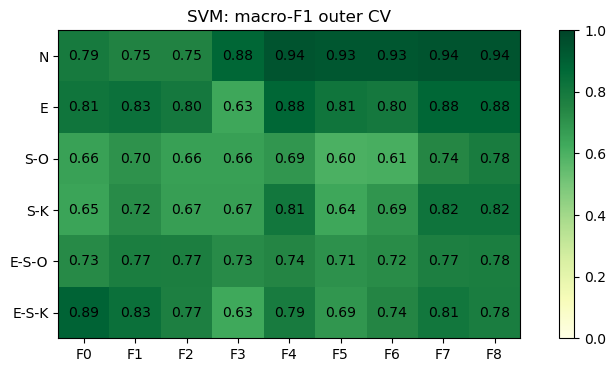

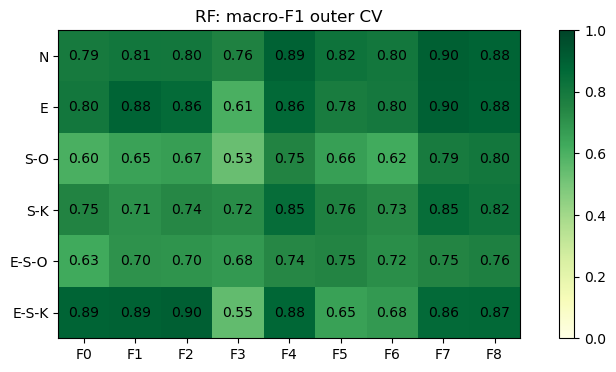

mean     std
axis    fixed model contrast                   
PCD     F0    RF    E - N        0.0122  0.0750
                    E-S-K - E    0.0840  0.0735
                    E-S-K - S-K  0.1344  0.1377
                    E-S-O - E   -0.1749  0.2145
                    E-S-O - S-O  0.0237  0.0899
...                                 ...     ...
feature S-O   SVM   F6 - F3     -0.0506  0.1933
                    F7 - F2      0.0852  0.0885
                    F7 - F5      0.1405  0.1998
                    F8 - F1      0.0821  0.0724
                    F8 - F6      0.1730  0.1613

[246 rows x 2 columns]

In [9]:
summary = score_df.groupby(['input','feature','model']).agg(
    macro_f1_mean=('macro_f1','mean'), macro_f1_std=('macro_f1','std'),
    accuracy_mean=('accuracy','mean'), total_s=('total_s','mean')).reset_index()
summary = summary.sort_values(['macro_f1_mean','input','feature','model'],ascending=[False,True,True,True])
summary.to_csv(OUT/'summary_108.csv',index=False)
display(summary.head(20))
for model in GRIDS:
    table = summary[summary.model.eq(model)].pivot(index='input',columns='feature',values='macro_f1_mean').reindex(CONDITIONS)
    fig,ax = plt.subplots(figsize=(10,4)); im=ax.imshow(table,vmin=0,vmax=1,cmap='YlGn')
    ax.set_xticks(range(9),table.columns); ax.set_yticks(range(6),table.index)
    for (r,k),v in np.ndenumerate(table.to_numpy()): ax.text(k,r,f'{v:.2f}',ha='center',va='center')
    ax.set_title(f'{model}: macro-F1 '+('SMOKE' if SMOKE_TEST else 'outer CV')); fig.colorbar(im,ax=ax); plt.show()
deltas=[]
for keys,d in score_df.groupby(['fold','feature','model']):
    indexed=d.set_index('input')
    for a,b in [('E','N'),('S-O','N'),('S-K','N'),('E-S-O','E'),('E-S-K','E'),('E-S-O','S-O'),('E-S-K','S-K')]:
        deltas.append(dict(axis='PCD',fold=keys[0],fixed=keys[1],model=keys[2],contrast=f'{a} - {b}',delta=indexed.loc[a,'macro_f1']-indexed.loc[b,'macro_f1']))
for keys,d in score_df.groupby(['fold','input','model']):
    indexed=d.set_index('feature')
    for a,b in [('F1','F0'),('F2','F0'),('F4','F0'),('F7','F2'),('F8','F1'),('F4','F3'),('F5','F3'),('F6','F3'),('F7','F5'),('F8','F6')]:
        deltas.append(dict(axis='feature',fold=keys[0],fixed=keys[1],model=keys[2],contrast=f'{a} - {b}',delta=indexed.loc[a,'macro_f1']-indexed.loc[b,'macro_f1']))
delta_df=pd.DataFrame(deltas); delta_df.to_csv(OUT/'paired_deltas.csv',index=False)
display(delta_df.groupby(['axis','fixed','model','contrast']).delta.agg(['mean','std']).round(4))

## 7. Error analysis: kelas paling banyak salah dan pasangan kebingungan

Pilih satu konfigurasi yang ingin dibahas (`ANALYSIS_KEY`) sebelum membaca detail kesalahan. Default menampilkan kombinasi teratas deskriptif, **bukan** test independen model terbaik. Untuk setiap model, tabel seluruh konfigurasi tetap disimpan. `jumlah_salah = support − benar` dan `error_rate = jumlah_salah / support` menjawab pertanyaan berbeda pada kelas tidak seimbang. Contoh salah diambil dari prediksi OOF, bukan prediksi training.

,kelas,support,jumlah_salah,error_rate,recall
5,Peperomium semangka,6,1,0.166667,0.833333
2,Kamboja jepang,9,1,0.111111,0.888889
0,Aglaonema,10,0,0.000000,1.000000
1,Daun nangka,9,0,0.000000,1.000000
3,Lidah metua,12,0,0.000000,1.000000
4,Paku tanduk rusa,14,0,0.000000,1.000000


Konfigurasi analisis: ('N', 'F4', 'SVM')
Kelas dengan jumlah salah terbanyak: Peperomium semangka, Kamboja jepang ; jumlah salah = 1
Kelas dengan error rate tertinggi: Peperomium semangka


,precision,recall,f1-score,support
Aglaonema,1.000000,1.000000,1.000000,10.000000
Daun nangka,1.000000,1.000000,1.000000,9.000000
Kamboja jepang,1.000000,0.888889,0.941176,9.000000
Lidah metua,0.857143,1.000000,0.923077,12.000000
Paku tanduk rusa,1.000000,1.000000,1.000000,14.000000
Peperomium semangka,1.000000,0.833333,0.909091,6.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.976190,0.953704,0.962224,60.000000
weighted avg,0.971429,0.966667,0.966701,60.000000


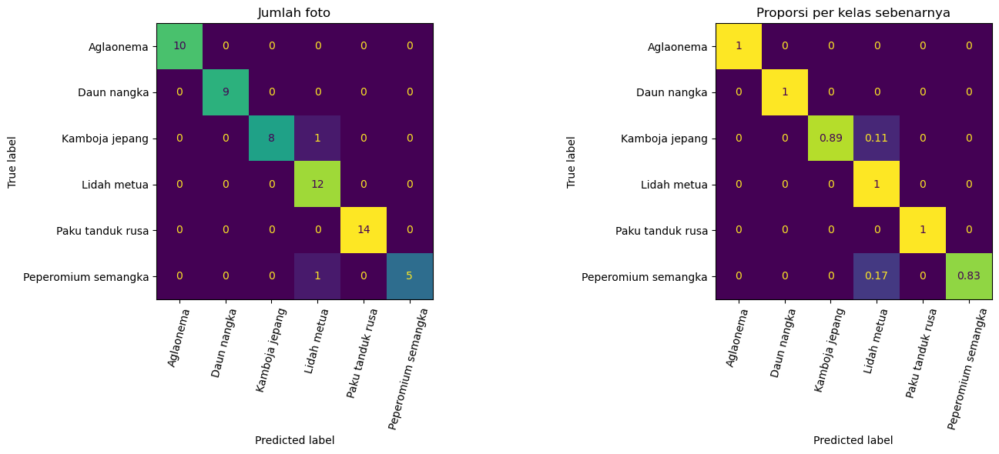

true                 pred       
Kamboja jepang       Lidah metua    1
Peperomium semangka  Lidah metua    1
Name: jumlah, dtype: int64

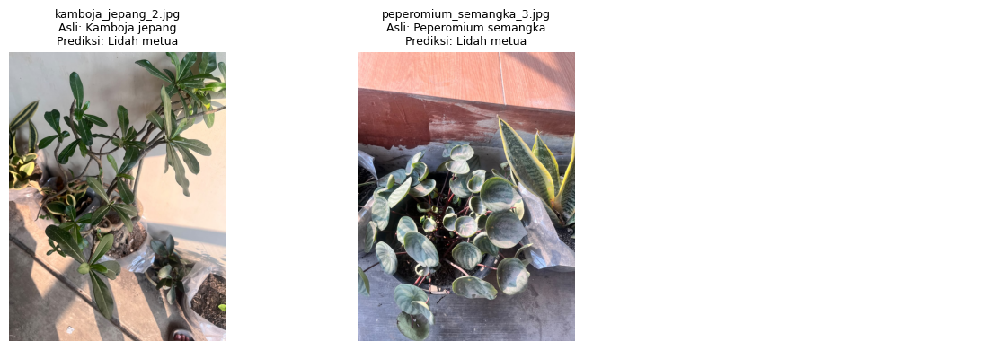

In [10]:
ANALYSIS_KEY = tuple(summary.iloc[0][['input','feature','model']])
c,f,model = ANALYSIS_KEY
def class_errors(d):
    rows=[]
    for label in LABELS:
        s=d[d.true.eq(label)]
        rows.append(dict(kelas=label,support=len(s),jumlah_salah=int((~s.correct).sum()),
            error_rate=float((~s.correct).mean()),recall=float(s.correct.mean())))
    return pd.DataFrame(rows).sort_values(['jumlah_salah','error_rate'],ascending=False)
all_class=[]
for (ci,fi,mi),d in pred_df.groupby(['input','feature','model']):
    t=class_errors(d); t['input']=ci; t['feature']=fi; t['model']=mi; all_class.append(t)
pd.concat(all_class).to_csv(OUT/'class_errors_all_108.csv',index=False)
d = pred_df[pred_df.input.eq(c)&pred_df.feature.eq(f)&pred_df.model.eq(model)].copy()
errors=class_errors(d); display(errors)
max_wrong=errors.jumlah_salah.max()
print('Konfigurasi analisis:',ANALYSIS_KEY)
print('Kelas dengan jumlah salah terbanyak:', ', '.join(errors.loc[errors.jumlah_salah.eq(max_wrong),'kelas']), '; jumlah salah =',max_wrong)
max_rate=errors.error_rate.max()
print('Kelas dengan error rate tertinggi:', ', '.join(errors.loc[errors.error_rate.eq(max_rate),'kelas']))
report=pd.DataFrame(classification_report(d.true,d.pred,labels=LABELS,output_dict=True,zero_division=0)).T
display(report); report.to_csv(OUT/'classification_report_selected.csv')
fig,axes=plt.subplots(1,2,figsize=(15,6))
for ax,norm in zip(axes,(None,'true')):
    ConfusionMatrixDisplay.from_predictions(d.true,d.pred,labels=LABELS,normalize=norm,ax=ax,xticks_rotation=75,colorbar=False)
    ax.set_title('Jumlah foto' if norm is None else 'Proporsi per kelas sebenarnya')
plt.tight_layout(); plt.show()
confusions=d[~d.correct].groupby(['true','pred']).size().rename('jumlah').sort_values(ascending=False)
display(confusions); confusions.to_csv(OUT/'confusion_pairs_selected.csv')
wrong=d[~d.correct].head(12)
if len(wrong):
    fig,axes=plt.subplots(int(np.ceil(len(wrong)/3)),3,figsize=(12,4*np.ceil(len(wrong)/3)),squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax,r in zip(axes.flat,wrong.itertuples()):
        i=int(meta.index[meta.image.eq(r.image)][0]); rgb,mask,_=processed(i,c)
        ax.imshow(rgb); ax.contour(mask,levels=[.5],colors='yellow',linewidths=.5) if mask.any() and not mask.all() else None
        ax.set_title(f'{r.image}\nAsli: {r.true}\nPrediksi: {r.pred}',fontsize=9)
    plt.tight_layout(); plt.show()
else: print('Tidak ada kesalahan OOF pada konfigurasi ini; belum membuktikan generalisasi tanaman baru.')

### 7b. Error analysis empat konfigurasi teratas tanpa training ulang



,input,feature,model,macro_f1_mean,macro_f1_std,accuracy_mean,total_s
0,N,F4,SVM,0.944444,0.124226,0.966667,0.154131
1,N,F7,SVM,0.944444,0.124226,0.966667,0.168839
2,N,F8,SVM,0.944444,0.124226,0.966667,0.171588
3,N,F5,SVM,0.930000,0.074079,0.933333,0.134654



Peringkat 1: ('N', 'F4', 'SVM') | 60 foto OOF


,precision,recall,f1-score,support
Aglaonema,1.000000,1.000000,1.000000,10.000000
Daun nangka,1.000000,1.000000,1.000000,9.000000
Kamboja jepang,1.000000,0.888889,0.941176,9.000000
Lidah metua,0.857143,1.000000,0.923077,12.000000
Paku tanduk rusa,1.000000,1.000000,1.000000,14.000000
Peperomium semangka,1.000000,0.833333,0.909091,6.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.976190,0.953704,0.962224,60.000000
weighted avg,0.971429,0.966667,0.966701,60.000000


,kelas,support,jumlah_salah,error_rate
5,Peperomium semangka,6,1,0.166667
2,Kamboja jepang,9,1,0.111111
1,Daun nangka,9,0,0.000000
0,Aglaonema,10,0,0.000000
3,Lidah metua,12,0,0.000000
4,Paku tanduk rusa,14,0,0.000000


,fold,profile,accuracy,macro_f1,params
8,0,2,1.000000,1.000000,"{""C"": 1, ""gamma"": 0.01}"
116,1,2,0.833333,0.722222,"{""C"": 1, ""gamma"": ""scale""}"
224,2,2,1.000000,1.000000,"{""C"": 1, ""gamma"": 0.01}"
332,3,2,1.000000,1.000000,"{""C"": 1, ""gamma"": 0.01}"
440,4,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"


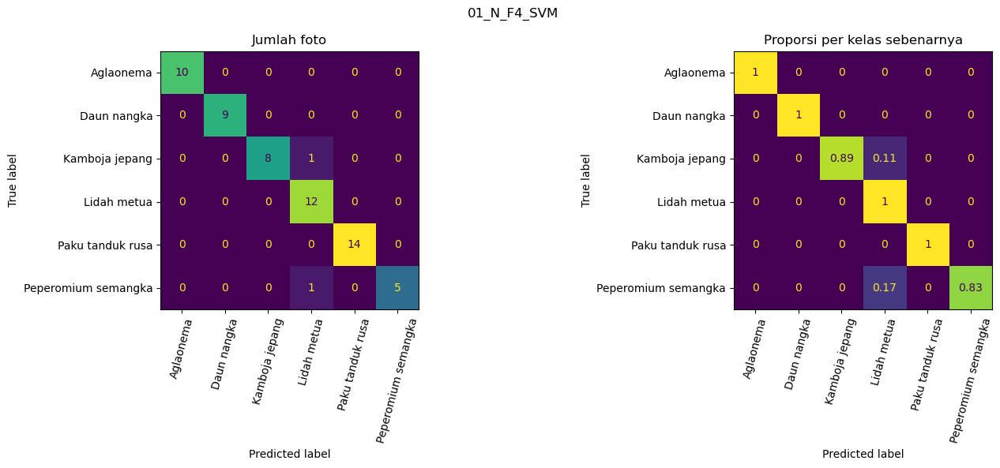

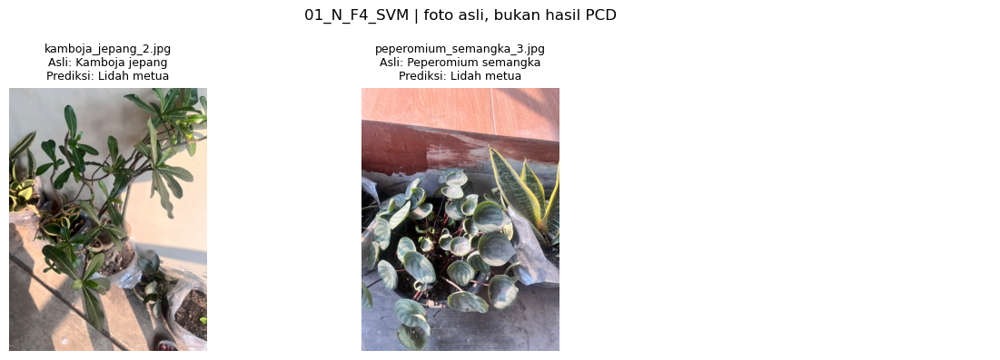


Peringkat 2: ('N', 'F7', 'SVM') | 60 foto OOF


,precision,recall,f1-score,support
Aglaonema,1.000000,1.000000,1.000000,10.000000
Daun nangka,1.000000,1.000000,1.000000,9.000000
Kamboja jepang,1.000000,0.888889,0.941176,9.000000
Lidah metua,0.857143,1.000000,0.923077,12.000000
Paku tanduk rusa,1.000000,1.000000,1.000000,14.000000
Peperomium semangka,1.000000,0.833333,0.909091,6.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.976190,0.953704,0.962224,60.000000
weighted avg,0.971429,0.966667,0.966701,60.000000


,kelas,support,jumlah_salah,error_rate
5,Peperomium semangka,6,1,0.166667
2,Kamboja jepang,9,1,0.111111
1,Daun nangka,9,0,0.000000
0,Aglaonema,10,0,0.000000
3,Lidah metua,12,0,0.000000
4,Paku tanduk rusa,14,0,0.000000


,fold,profile,accuracy,macro_f1,params
14,0,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"
122,1,2,0.833333,0.722222,"{""C"": 1, ""gamma"": ""scale""}"
230,2,2,1.000000,1.000000,"{""C"": 1, ""gamma"": 0.01}"
338,3,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"
446,4,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"


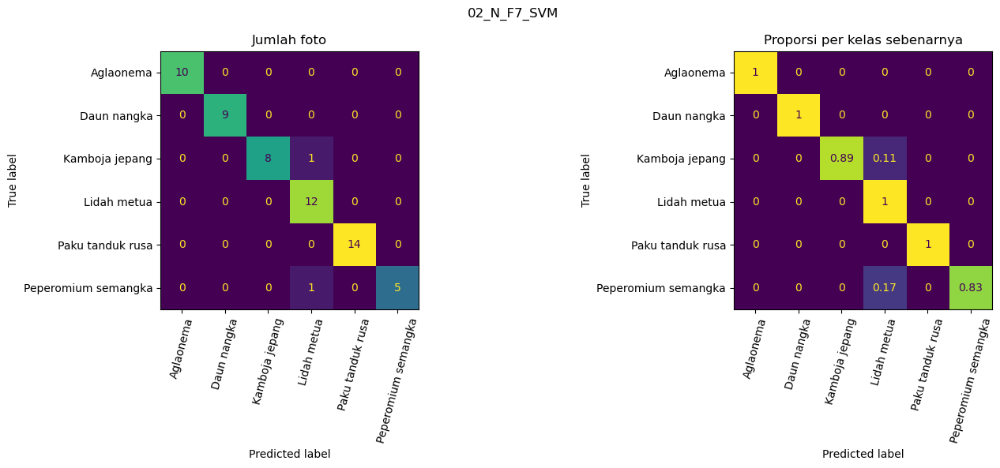

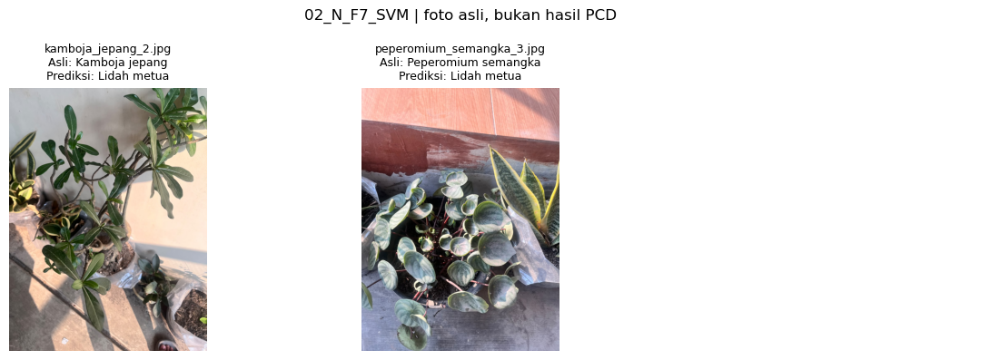


Peringkat 3: ('N', 'F8', 'SVM') | 60 foto OOF


,precision,recall,f1-score,support
Aglaonema,1.000000,1.000000,1.000000,10.000000
Daun nangka,1.000000,1.000000,1.000000,9.000000
Kamboja jepang,1.000000,0.888889,0.941176,9.000000
Lidah metua,0.857143,1.000000,0.923077,12.000000
Paku tanduk rusa,1.000000,1.000000,1.000000,14.000000
Peperomium semangka,1.000000,0.833333,0.909091,6.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.976190,0.953704,0.962224,60.000000
weighted avg,0.971429,0.966667,0.966701,60.000000


,kelas,support,jumlah_salah,error_rate
5,Peperomium semangka,6,1,0.166667
2,Kamboja jepang,9,1,0.111111
1,Daun nangka,9,0,0.000000
0,Aglaonema,10,0,0.000000
3,Lidah metua,12,0,0.000000
4,Paku tanduk rusa,14,0,0.000000


,fold,profile,accuracy,macro_f1,params
16,0,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"
124,1,2,0.833333,0.722222,"{""C"": 1, ""gamma"": ""scale""}"
232,2,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"
340,3,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"
448,4,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"


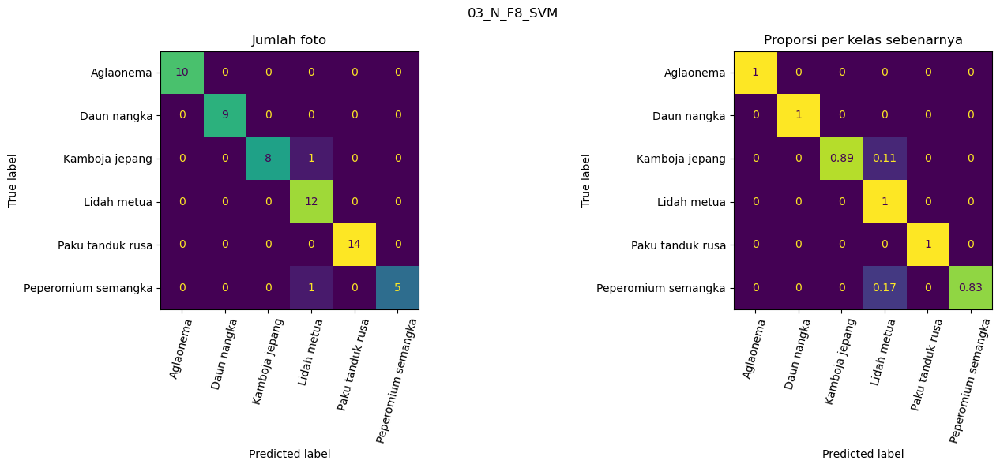

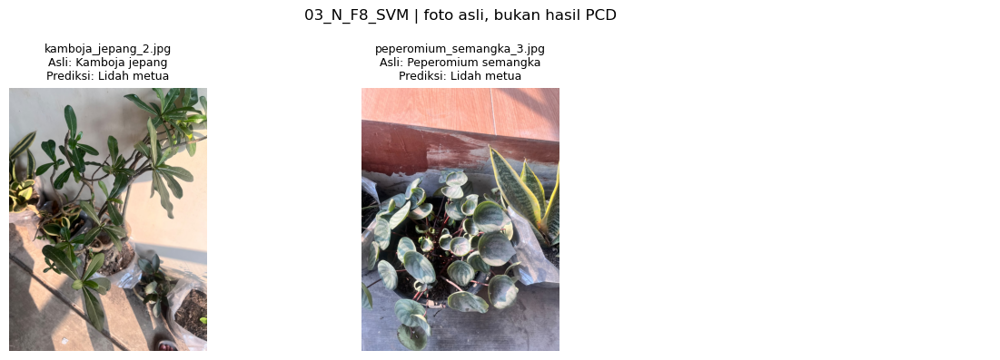


Peringkat 4: ('N', 'F5', 'SVM') | 60 foto OOF


,precision,recall,f1-score,support
Aglaonema,0.909091,1.000000,0.952381,10.000000
Daun nangka,0.875000,0.777778,0.823529,9.000000
Kamboja jepang,0.888889,0.888889,0.888889,9.000000
Lidah metua,1.000000,1.000000,1.000000,12.000000
Paku tanduk rusa,1.000000,0.928571,0.962963,14.000000
Peperomium semangka,0.857143,1.000000,0.923077,6.000000
accuracy,0.933333,0.933333,0.933333,0.933333
macro avg,0.921687,0.932540,0.925140,60.000000
weighted avg,0.935146,0.933333,0.932592,60.000000


,kelas,support,jumlah_salah,error_rate
1,Daun nangka,9,2,0.222222
2,Kamboja jepang,9,1,0.111111
4,Paku tanduk rusa,14,1,0.071429
0,Aglaonema,10,0,0.000000
3,Lidah metua,12,0,0.000000
5,Peperomium semangka,6,0,0.000000


,fold,profile,accuracy,macro_f1,params
10,0,2,1.000000,1.000000,"{""C"": 10, ""gamma"": 0.01}"
118,1,2,0.833333,0.827778,"{""C"": 10, ""gamma"": 0.01}"
226,2,2,0.916667,0.888889,"{""C"": 1, ""gamma"": ""scale""}"
334,3,2,0.916667,0.933333,"{""C"": 1, ""gamma"": 0.01}"
442,4,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"


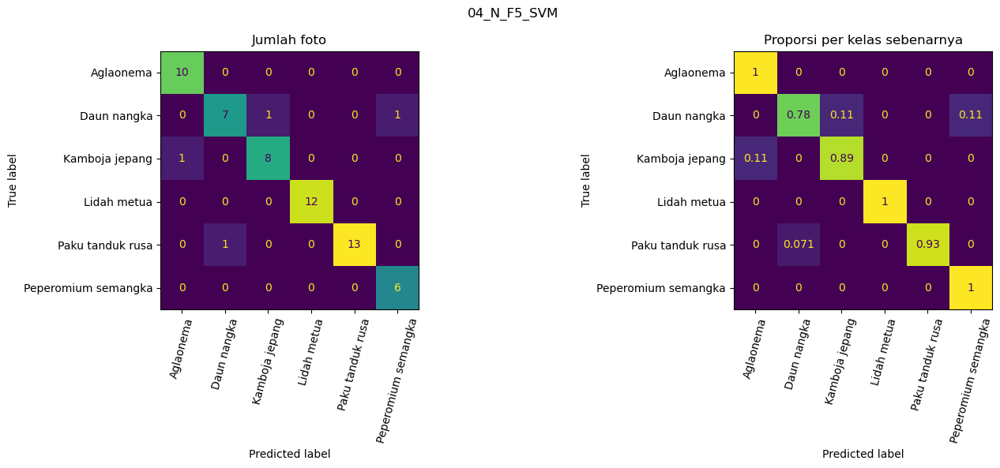

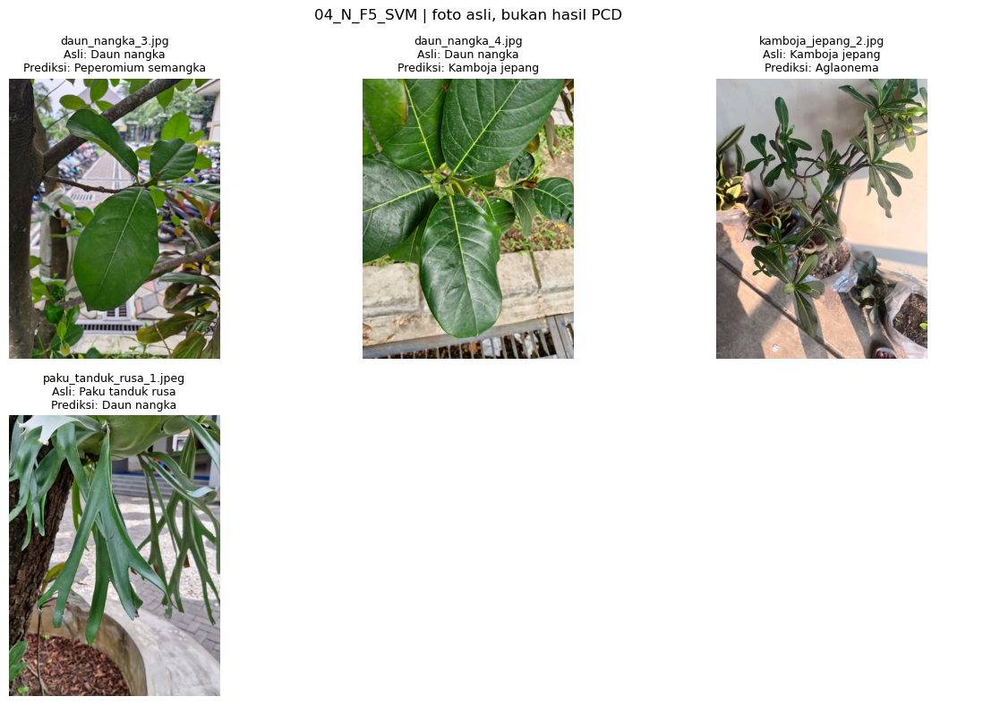

Ringkasan empat konfigurasi:


,input,feature,model,macro_f1_mean,macro_f1_std,macro_f1_pooled_oof,jumlah_salah,jumlah_foto
0,N,F4,SVM,0.944444,0.124226,0.962224,2,60
1,N,F7,SVM,0.944444,0.124226,0.962224,2,60
2,N,F8,SVM,0.944444,0.124226,0.962224,2,60
3,N,F5,SVM,0.930000,0.074079,0.925140,4,60


Foto yang salah pada setidaknya satu konfigurasi:


,image,true,01_N_F4_SVM_pred,01_N_F4_SVM_correct,02_N_F7_SVM_pred,02_N_F7_SVM_correct,03_N_F8_SVM_pred,03_N_F8_SVM_correct,04_N_F5_SVM_pred,04_N_F5_SVM_correct,jumlah_konfigurasi_salah
20,kamboja_jepang_2.jpg,Kamboja jepang,Lidah metua,False,Lidah metua,False,Lidah metua,False,Aglaonema,False,4
56,peperomium_semangka_3.jpg,Peperomium semangka,Lidah metua,False,Lidah metua,False,Lidah metua,False,Peperomium semangka,True,3
12,daun_nangka_3.jpg,Daun nangka,Daun nangka,True,Daun nangka,True,Daun nangka,True,Peperomium semangka,False,1
13,daun_nangka_4.jpg,Daun nangka,Daun nangka,True,Daun nangka,True,Daun nangka,True,Kamboja jepang,False,1
40,paku_tanduk_rusa_1.jpeg,Paku tanduk rusa,Paku tanduk rusa,True,Paku tanduk rusa,True,Paku tanduk rusa,True,Daun nangka,False,1


Hasil tersimpan: e:\PCD\Project Akhir\Notebook\hasil_ml_full_aug\error_analysis_top4
Analisis deskriptif pada hasil OOF yang sudah ada; tidak ada training ulang atau tuning tambahan.


In [11]:
# Mandiri: jalankan cell ini saja setelah hasil benchmark tersedia; tidak ada fit/training.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

EA_FOLDER = Path(globals().get('OUT',Path('hasil_ml_full_aug'))).name
EA_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p/'Notebook'/EA_FOLDER/'oof_predictions.csv').is_file()), None)
assert EA_ROOT is not None, 'Hasil OOF full belum ditemukan. Periksa lokasi hasil benchmark.'
EA_RESULTS = EA_ROOT/'Notebook'/EA_FOLDER
EA_OUT = EA_RESULTS/'error_analysis_top4'
EA_OUT.mkdir(parents=True, exist_ok=True)
ea_summary = pd.read_csv(EA_RESULTS/'summary_108.csv')
ea_pred = pd.read_csv(EA_RESULTS/'oof_predictions.csv')
ea_metrics = pd.read_csv(EA_RESULTS/'metrics_per_fold.csv')
ea_pred['correct'] = ea_pred['true'].eq(ea_pred['pred'])
ea_labels = sorted(ea_pred['true'].unique())
# Ikuti empat baris teratas pada summary yang tersimpan, termasuk urutan tie-nya.
ea_top = ea_summary.head(4).copy()
assert len(ea_top) == 4, 'Diperlukan setidaknya empat konfigurasi.'
display(ea_top)
ea_class_tables, ea_fold_tables, ea_overview = [], [], []
ea_comparison = None

for ea_rank, ea_row in enumerate(ea_top.itertuples(index=False), start=1):
    ea_key = (ea_row.input, ea_row.feature, ea_row.model)
    ea_tag = f'{ea_rank:02d}_{ea_row.input}_{ea_row.feature}_{ea_row.model}'
    ea_dir = EA_OUT/ea_tag
    ea_dir.mkdir(exist_ok=True)
    ea_d = ea_pred.loc[(ea_pred['input']==ea_key[0]) &
                       (ea_pred['feature']==ea_key[1]) & (ea_pred['model']==ea_key[2])].copy()
    assert len(ea_d) and not ea_d['image'].duplicated().any(), 'OOF harus satu prediksi per foto.'
    print(f'\nPeringkat {ea_rank}: {ea_key} | {len(ea_d)} foto OOF')
    ea_report = pd.DataFrame(classification_report(
        ea_d['true'], ea_d['pred'], labels=ea_labels,
        output_dict=True, zero_division=0)).T
    ea_report.to_csv(ea_dir/'classification_report.csv')
    display(ea_report)
    ea_class = pd.DataFrame([
        dict(kelas=ea_label, support=int((ea_d['true']==ea_label).sum()),
             jumlah_salah=int(((ea_d['true']==ea_label)&~ea_d['correct']).sum()))
        for ea_label in ea_labels])
    ea_class['error_rate'] = ea_class['jumlah_salah']/ea_class['support'].replace(0,np.nan)
    ea_class.to_csv(ea_dir/'class_errors.csv',index=False)
    ea_class_tables.append(ea_class.assign(input=ea_key[0],feature=ea_key[1],model=ea_key[2]))
    display(ea_class.sort_values('jumlah_salah',ascending=False))
    ea_folds = ea_metrics.loc[(ea_metrics['input']==ea_key[0]) &
                             (ea_metrics['feature']==ea_key[1]) & (ea_metrics['model']==ea_key[2])]
    ea_folds.to_csv(ea_dir/'metrics_per_fold.csv',index=False)
    ea_fold_tables.append(ea_folds)
    display(ea_folds[['fold','profile','accuracy','macro_f1','params']])
    ea_overview.append(dict(input=ea_key[0],feature=ea_key[1],model=ea_key[2],
        macro_f1_mean=ea_row.macro_f1_mean,macro_f1_std=ea_row.macro_f1_std,
        macro_f1_pooled_oof=f1_score(ea_d['true'],ea_d['pred'],labels=ea_labels,
                                    average='macro',zero_division=0),
        jumlah_salah=int((~ea_d['correct']).sum()),jumlah_foto=len(ea_d)))
    ea_fig, ea_axes = plt.subplots(1,2,figsize=(15,6))
    for ea_ax,ea_norm in zip(ea_axes,(None,'true')):
        ConfusionMatrixDisplay.from_predictions(ea_d['true'],ea_d['pred'],labels=ea_labels,
            normalize=ea_norm,ax=ea_ax,xticks_rotation=75,colorbar=False)
        ea_ax.set_title('Jumlah foto' if ea_norm is None else 'Proporsi per kelas sebenarnya')
    ea_fig.suptitle(ea_tag)
    ea_fig.tight_layout()
    ea_fig.savefig(ea_dir/'confusion_matrix.png',dpi=140,bbox_inches='tight')
    plt.show(); plt.close(ea_fig)
    ea_wrong = ea_d.loc[~ea_d['correct']].sort_values(['true','image'])
    ea_wrong.to_csv(ea_dir/'wrong_predictions.csv',index=False)
    ea_pairs = ea_wrong.groupby(['true','pred']).size().rename('jumlah').reset_index()
    ea_pairs.sort_values('jumlah',ascending=False).to_csv(ea_dir/'confusion_pairs.csv',index=False)
    if len(ea_wrong):
        # Foto asli sebagai contoh kesalahan; tidak menghitung ulang PCD atau fitur.
        ea_n = min(12,len(ea_wrong))
        ea_fig,ea_axes = plt.subplots(int(np.ceil(ea_n/3)),3,
            figsize=(12,4*int(np.ceil(ea_n/3))),squeeze=False)
        for ea_ax in ea_axes.flat: ea_ax.axis('off')
        for ea_ax,ea_item in zip(ea_axes.flat,ea_wrong.head(ea_n).itertuples(index=False)):
            ea_path = EA_ROOT/'Dataset'/str(ea_item.true)/str(ea_item.image)
            if ea_path.is_file():
                with Image.open(ea_path) as ea_im:
                    ea_ax.imshow(ImageOps.exif_transpose(ea_im).convert('RGB'))
            else:
                ea_ax.text(.5,.5,'Foto tidak ditemukan',ha='center')
            ea_ax.set_title(f'{ea_item.image}\nAsli: {ea_item.true}\nPrediksi: {ea_item.pred}',fontsize=9)
        ea_fig.suptitle(ea_tag+' | foto asli, bukan hasil PCD')
        ea_fig.tight_layout()
        ea_fig.savefig(ea_dir/'wrong_examples_original.png',dpi=130,bbox_inches='tight')
        plt.show(); plt.close(ea_fig)
    else:
        print('Tidak ada kesalahan OOF pada konfigurasi ini.')
    ea_piece = ea_d[['image','true','pred','correct']].rename(
        columns={'pred':ea_tag+'_pred','correct':ea_tag+'_correct'})
    ea_comparison = ea_piece if ea_comparison is None else ea_comparison.merge(
        ea_piece,on=['image','true'],how='outer',validate='one_to_one')

ea_correct_cols = [ea_col for ea_col in ea_comparison if ea_col.endswith('_correct')]
assert ea_comparison[ea_correct_cols].notna().all().all(), 'Foto OOF antarkonfigurasi tidak sama.'
ea_comparison['jumlah_konfigurasi_salah'] = (~ea_comparison[ea_correct_cols].astype(bool)).sum(axis=1)
ea_comparison = ea_comparison.sort_values(['jumlah_konfigurasi_salah','image'],ascending=[False,True])
ea_comparison.to_csv(EA_OUT/'perbandingan_prediksi_per_foto.csv',index=False)
pd.concat(ea_class_tables,ignore_index=True).to_csv(EA_OUT/'class_errors_top4.csv',index=False)
pd.concat(ea_fold_tables,ignore_index=True).to_csv(EA_OUT/'metrics_per_fold_top4.csv',index=False)
ea_overview = pd.DataFrame(ea_overview)
ea_overview.to_csv(EA_OUT/'ringkasan_top4.csv',index=False)
print('Ringkasan empat konfigurasi:')
display(ea_overview)
print('Foto yang salah pada setidaknya satu konfigurasi:')
display(ea_comparison.loc[ea_comparison['jumlah_konfigurasi_salah']>0])
print('Hasil tersimpan:',EA_OUT)
print('Analisis deskriptif pada hasil OOF yang sudah ada; tidak ada training ulang atau tuning tambahan.')


## 8. Feature importance pada data outer-evaluation

Permutation importance memakai **penurunan macro-F1** saat satu fitur diacak pada foto outer-evaluation, terpisah dari fitting. Disediakan untuk SVM dan RF pada paket/input analisis. Nilai negatif boleh terjadi; fitur berkorelasi dapat saling menggantikan sehingga importance bukan kausalitas. Tambahkan pengacakan **blok** warna/Sobel/Canny/BoVW untuk menguji kontribusi kelompok.

Word BoVW dan profil/dimensi dapat berbeda antar fold: importance individual ditampilkan per fold dan tidak merata-ratakan word indeks lintas kamus. Importance blok boleh diringkas antarfold. Untuk RF, impurity importance disimpan sebagai tambahan dengan bias terhadap fitur kontinu; interpretasi utama memakai permutation OOF. Foto evaluasi dipakai untuk penjelasan deskriptif ini, tidak untuk melatih ulang atau mengganti parameter.

mean       std
model block                    
RF    bovw   0.115667  0.095394
      color  0.668952  0.086346
SVM   bovw   0.422563  0.133508
      color  0.552471  0.074995

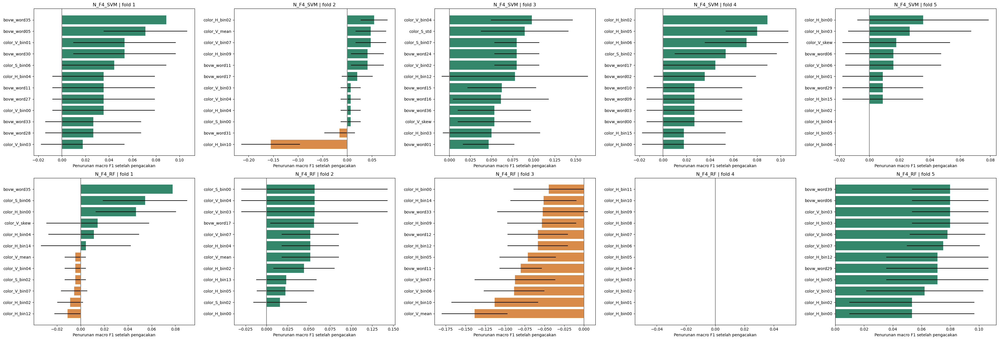

,no_sift,empty_edge
input,,
E,0.000000,0.0
E-S-K,0.150000,0.0
E-S-O,0.016667,0.0
N,0.000000,0.0
S-K,0.133333,0.0
S-O,0.050000,0.0


Lulus pemeriksaan: 540 baris fold, 6480 prediksi OOF; output: e:\PCD\Project Akhir\Notebook\hasil_ml_full_aug
Hasil eksploratif; validasi tanaman independen bergantung plant_id dan QC.


In [12]:
importance_rows, block_rows, mdi_rows = [],[],[]
for model in ('SVM','RF'):
    for fold,(tr,te) in enumerate(outer):
        est,pid=fitted[(fold,c,f,model)]
        X=matrix(c,pid,tr,f); feature_names=names(pid,f)
        imp=permutation_importance(est,X[te],y[te],scoring='f1_macro',n_repeats=PERM_REPEATS,random_state=SEED,n_jobs=1)
        for n,mean,std in zip(feature_names,imp.importances_mean,imp.importances_std):
            importance_rows.append(dict(model=model,fold=fold,input=c,feature=f,name=n,mean=mean,std=std,profile=pid))
        base=f1_score(y[te],est.predict(X[te]),labels=LABELS,average='macro',zero_division=0)
        rng=np.random.default_rng(SEED)
        for block in PACKAGES[f]:
            cols=[j for j,n in enumerate(feature_names) if n.startswith(block+'_')]
            drops=[]
            for repeat in range(PERM_REPEATS):
                xp=X[te].copy(); order=rng.permutation(len(te))
                xp[:,cols]=xp[order][:,cols]
                drops.append(base-f1_score(y[te],est.predict(xp),labels=LABELS,average='macro',zero_division=0))
            block_rows.append(dict(model=model,fold=fold,block=block,mean=np.mean(drops),std=np.std(drops)))
        if model=='RF':
            mdi_rows.extend(dict(fold=fold,name=n,importance=v) for n,v in zip(feature_names,est[-1].feature_importances_))
imp_df=pd.DataFrame(importance_rows); imp_df.to_csv(OUT/'permutation_importance_by_fold.csv',index=False)
block_df=pd.DataFrame(block_rows); block_df.to_csv(OUT/'block_importance.csv',index=False)
pd.DataFrame(mdi_rows).to_csv(OUT/'rf_impurity_importance_by_fold.csv',index=False)
display(block_df.groupby(['model','block'])['mean'].agg(['mean','std']))
fig,axes=plt.subplots(2,len(outer),figsize=(7*len(outer),12),squeeze=False)
for row,model in enumerate(('SVM','RF')):
    for fold in range(len(outer)):
        # Konsisten dengan 8b: besar perubahan absolut, tanda asli tetap dipertahankan.
        top=(imp_df[imp_df.model.eq(model)&imp_df.fold.eq(fold)]
             .assign(abs_mean=lambda d:d['mean'].abs())
             .nlargest(12,'abs_mean').sort_values('mean'))
        axes[row,fold].barh(top['name'],top['mean'],xerr=top['std'],
            color=np.where(top['mean']<0,'#D98C4A','#34876A'))
        axes[row,fold].axvline(0,color='gray')
        axes[row,fold].set_title(f'{c}_{f}_{model} | fold {fold+1}')
        axes[row,fold].set_xlabel('Penurunan macro F1 setelah pengacakan')
plt.tight_layout(); plt.show()
raw_audit = pd.DataFrame([dict(image=meta.iloc[i].image,input=ci,n_sift=len(raw_features(i,ci,0)['desc']),
    edge_domain_empty=bool(np.isnan(raw_features(i,ci,0)['sobel']).all())) for ci in CONDITIONS for i in range(len(meta))])
raw_audit.to_csv(OUT/'feature_qc_profile0.csv',index=False)
display(raw_audit.groupby('input').agg(no_sift=('n_sift',lambda s:float(s.eq(0).mean())),empty_edge=('edge_domain_empty','mean')))
print('Lulus pemeriksaan:',len(score_df),'baris fold,',len(pred_df),'prediksi OOF; output:',OUT)
print('SMOKE TEST saja. Ubah SMOKE_TEST=False dan gunakan kernel ai_env untuk full training.' if SMOKE_TEST else 'Hasil eksploratif; validasi tanaman independen bergantung plant_id dan QC.')

### 8b. Feature importance skor tertinggi selain F4




Konfigurasi seri pada skor tertinggi, selain F4:


,input,feature,model,macro_f1_mean,macro_f1_std,accuracy_mean,total_s
1,N,F7,SVM,0.944444,0.124226,0.966667,0.168839
2,N,F8,SVM,0.944444,0.124226,0.966667,0.171588


Analisis: N_F7_SVM


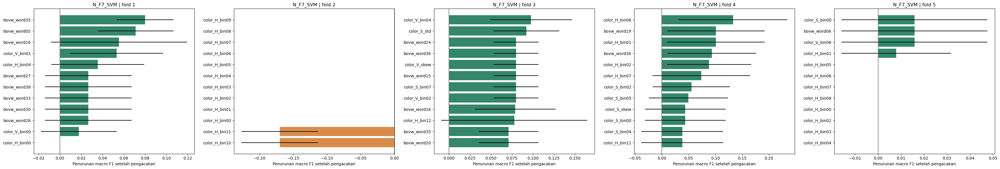

Analisis: N_F8_SVM


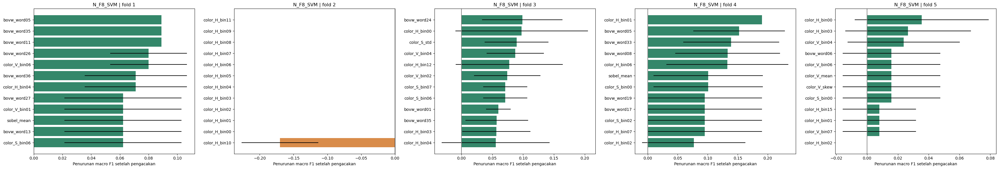

,input,feature,model,block,importance_mean,importance_std_across_folds
0,N,F7,SVM,bovw,0.319651,0.146162
1,N,F7,SVM,canny,0.054690,0.040242
2,N,F7,SVM,color,0.484540,0.095240
3,N,F8,SVM,bovw,0.317524,0.146109
4,N,F8,SVM,color,0.483071,0.094512
5,N,F8,SVM,sobel,0.073897,0.054477


Hasil: e:\PCD\Project Akhir\Notebook\hasil_ml_full_aug\feature_importance_best_non_f4


In [13]:
# 8b - Feature importance tertinggi selain F4. Semua kode ada di cell ini.
"""Permutation importance konfigurasi skor tertinggi selain F4; tanpa refit."""
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score

fi_missing = [k for k in ('fitted','outer','matrix','names','PACKAGES','y','LABELS','OUT','SEED','encode') if k not in globals()]
if fi_missing:
    raise RuntimeError('Gunakan kernel training yang masih aktif. Objek tidak tersedia: '+', '.join(fi_missing)+'. Tidak melakukan training ulang.')
fi_summary = pd.read_csv(Path(OUT)/'summary_108.csv')
fi_targets = fi_summary.loc[np.isclose(fi_summary.macro_f1_mean,fi_summary.macro_f1_mean.max(),rtol=0,atol=1e-12) & fi_summary.feature.ne('F4')].copy()
print('Konfigurasi seri pada skor tertinggi, selain F4:')
display(fi_targets)
fi_destination = Path(OUT)/'feature_importance_best_non_f4'
fi_destination.mkdir(exist_ok=True)
fi_records, fi_block_records = [], []
def fi_scoring(estimator, X_eval, y_eval):
    # Callable langsung: tidak membawa default pos_label=1 dari make_scorer.
    return f1_score(y_eval, estimator.predict(X_eval), labels=LABELS,
                    average='macro', zero_division=0)
fi_repeats = int(globals().get('PERM_REPEATS',10))

def fi_cached_matrix(condition,profile,train,package):
    # Cache miss akan masuk ke body encode; hentikan sebelum kamus BoVW dilatih.
    original_code = encode.__wrapped__.__code__
    previous_profile = sys.getprofile()
    def guard(frame,event,arg):
        if event == 'call' and frame.f_code is original_code:
            raise RuntimeError('Cache fitur/BoVW untuk konfigurasi ini tidak tersedia. Berhenti tanpa training ulang.')
    try:
        sys.setprofile(guard)
        return matrix(condition,profile,train,package)
    finally:
        sys.setprofile(previous_profile)

for fi_row in fi_targets.itertuples(index=False):
    fi_tag = f'{fi_row.input}_{fi_row.feature}_{fi_row.model}'
    print('Analisis:',fi_tag,flush=True)
    fi_fig, fi_axes = plt.subplots(1,len(outer),figsize=(7*len(outer),6),squeeze=False)
    for fi_fold,(fi_train,fi_test) in enumerate(outer):
        fi_key = (fi_fold,fi_row.input,fi_row.feature,fi_row.model)
        if fi_key not in fitted:
            raise RuntimeError(f'Model tidak tersedia: {fi_key}. Tidak melakukan training ulang.')
        fi_est,fi_pid = fitted[fi_key]
        fi_X = fi_cached_matrix(fi_row.input,fi_pid,fi_train,fi_row.feature)
        fi_names = names(fi_pid,fi_row.feature)
        fi_result = permutation_importance(fi_est,fi_X[fi_test],y[fi_test],scoring=fi_scoring,
            n_repeats=fi_repeats,random_state=SEED,n_jobs=1)
        fi_table = pd.DataFrame({'name':fi_names,'mean':fi_result.importances_mean,'std':fi_result.importances_std})
        fi_table = fi_table.assign(input=fi_row.input,feature=fi_row.feature,model=fi_row.model,fold=fi_fold,profile=fi_pid)
        fi_records.append(fi_table)
        # Pilih perubahan terbesar berdasarkan absolut, tetapi pertahankan tanda asli.
        fi_top = fi_table.assign(abs_mean=fi_table['mean'].abs()).nlargest(12,'abs_mean').sort_values('mean')
        fi_axis = fi_axes[0,fi_fold]
        fi_axis.barh(fi_top['name'],fi_top['mean'],xerr=fi_top['std'],
            color=np.where(fi_top['mean']<0,'#D98C4A','#34876A'))
        fi_axis.axvline(0,color='gray')
        fi_axis.set_title(f'{fi_tag} | fold {fi_fold+1}')
        fi_axis.set_xlabel('Penurunan macro F1 setelah pengacakan')
        fi_base = f1_score(y[fi_test],fi_est.predict(fi_X[fi_test]),labels=LABELS,average='macro',zero_division=0)
        fi_rng = np.random.default_rng(SEED)
        for fi_block in PACKAGES[fi_row.feature]:
            fi_cols = [j for j,name in enumerate(fi_names) if name.startswith(fi_block+'_')]
            assert fi_cols,fi_block
            fi_drops=[]
            for fi_repeat in range(fi_repeats):
                fi_permuted = fi_X[fi_test].copy()
                fi_order = fi_rng.permutation(len(fi_test))
                fi_permuted[:,fi_cols] = fi_permuted[fi_order][:,fi_cols]
                fi_drops.append(fi_base-f1_score(y[fi_test],fi_est.predict(fi_permuted),labels=LABELS,average='macro',zero_division=0))
            fi_block_records.append(dict(input=fi_row.input,feature=fi_row.feature,model=fi_row.model,
                fold=fi_fold,profile=fi_pid,block=fi_block,mean=float(np.mean(fi_drops)),std=float(np.std(fi_drops))))
    fi_fig.tight_layout()
    fi_fig.savefig(fi_destination/(fi_tag+'_importance_by_fold.png'),dpi=140,bbox_inches='tight')
    plt.show(); plt.close(fi_fig)
if fi_records:
    pd.concat(fi_records,ignore_index=True).to_csv(fi_destination/'permutation_importance_by_fold.csv',index=False)
    fi_blocks_df = pd.DataFrame(fi_block_records)
    fi_blocks_df.to_csv(fi_destination/'block_importance_by_fold.csv',index=False)
    fi_block_summary = fi_blocks_df.groupby(['input','feature','model','block']).agg(
        importance_mean=('mean','mean'),importance_std_across_folds=('mean','std')).reset_index()
    fi_block_summary.to_csv(fi_destination/'block_importance_summary.csv',index=False)
    fi_targets.to_csv(fi_destination/'selected_configurations.csv',index=False)
    display(fi_block_summary)
    print('Hasil:',fi_destination)
else:
    print('Tidak ada konfigurasi tertinggi selain F4.')
